<!-- CELLA 1 -->

# Fake News Classification
## Analisi esplorativa e classificazione automatica di notizie vere e false

### Veridian Analytics

L'obiettivo del progetto è sviluppare un sistema di Natural Language Processing in grado di classificare articoli di news in lingua inglese come **veri (TRUE)** o **falsi (FAKE)**.

Il lavoro seguirà le principali fasi di un problema di classificazione testuale:

1. esplorazione e analisi dei dati;
2. individuazione di eventuali differenze o bias tra le fonti;
3. preprocessing e pulizia del testo;
4. rappresentazione numerica tramite Bag of Words;
5. addestramento e confronto di modelli di classificazione;
6. valutazione su dati non utilizzati durante l'addestramento;
7. analisi degli errori e dei possibili source bias;
8. esportazione del modello per il successivo utilizzo nell'estensione Chrome.

Particolare attenzione sarà dedicata all'interpretabilità dei risultati, verificando che il modello non impari semplicemente a distinguere la provenienza editoriale degli articoli anziché la loro attendibilità.

<!-- CELLA 2 -->

# 1. Caricamento e prima ispezione dei dati

Il dataset è distribuito sotto forma di archivio ZIP contenente due file separati: uno relativo alle notizie false e uno alle notizie verificate.

Per rendere il notebook completamente riproducibile, il pacchetto dati viene scaricato automaticamente dalla fonte fornita, senza richiedere il caricamento manuale dei file.

Prima di procedere con l'analisi verifichiamo che il download e l'estrazione siano avvenuti correttamente.

In [ ]:
# CELLA 3

import os
import zipfile
import urllib.request
import shutil

# URL pubblico del dataset
dataset_url = "https://proai-datasets.s3.eu-west-3.amazonaws.com/fake_news.zip"

# Percorsi utilizzati nell'ambiente Colab
zip_path = "/content/fake_news.zip"
extract_folder = "/content/fake_news_data"

# Rimuoviamo un'eventuale precedente estrazione,
# così il notebook parte sempre da una situazione pulita
if os.path.exists(extract_folder):
    shutil.rmtree(extract_folder)

os.makedirs(extract_folder)

# Download automatico del dataset
urllib.request.urlretrieve(dataset_url, zip_path)

# Estrazione dei file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

# Verifica del contenuto
print("Dataset scaricato ed estratto correttamente.")
print("\nFile presenti nel pacchetto:")

for filename in sorted(os.listdir(extract_folder)):
    print("-", filename)

Dataset scaricato ed estratto correttamente.

File presenti nel pacchetto:
- Fake.csv
- True.csv


<!-- CELLA 4 -->

## 1.1 Lettura dei due archivi

Carichiamo separatamente i file contenenti le notizie false e quelle vere.

In questa fase osserviamo soltanto la struttura originale dei dati, senza effettuare trasformazioni. Questo permette di verificare:

- il numero di articoli presenti in ciascun archivio;
- le colonne disponibili;
- il formato dei contenuti;
- eventuali differenze evidenti tra le due fonti.

In [ ]:
# CELLA 5

import pandas as pd

# Percorsi dei due file
fake_path = os.path.join(extract_folder, "Fake.csv")
true_path = os.path.join(extract_folder, "True.csv")

# Caricamento dei dataset
fake_df = pd.read_csv(fake_path)
true_df = pd.read_csv(true_path)

# Dimensioni dei dataset
print("DIMENSIONI DEI DATASET")
print("----------------------")
print("Fake:", fake_df.shape)
print("True:", true_df.shape)

# Colonne disponibili
print("\nCOLONNE")
print("-------")
print("Fake:", list(fake_df.columns))
print("True:", list(true_df.columns))

# Prime righe
print("\nPRIME 3 RIGHE - FAKE")
display(fake_df.head(3))

print("\nPRIME 3 RIGHE - TRUE")
display(true_df.head(3))

DIMENSIONI DEI DATASET
----------------------
Fake: (23481, 4)
True: (21417, 4)

COLONNE
-------
Fake: ['title', 'text', 'subject', 'date']
True: ['title', 'text', 'subject', 'date']

PRIME 3 RIGHE - FAKE


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"



PRIME 3 RIGHE - TRUE


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"


<!-- CELLA 6 -->

### Prime osservazioni sulla struttura dei dati

I due archivi presentano la stessa struttura, composta dalle colonne `title`, `text`, `subject` e `date`.

Il dataset delle notizie false contiene **23.481 articoli**, mentre quello delle notizie vere ne contiene **21.417**. Le due classi risultano quindi abbastanza bilanciate, anche se le fake news sono leggermente più numerose.

Già dalla prima ispezione emerge inoltre un possibile elemento di **source bias**: alcuni articoli dell'archivio TRUE iniziano con formule editoriali come `WASHINGTON (Reuters) -`. Se questa caratteristica fosse presente sistematicamente soltanto negli articoli veri, un classificatore potrebbe imparare a riconoscere la fonte anziché l'attendibilità della notizia.

Questo aspetto verrà analizzato più approfonditamente nelle sezioni successive.

In [ ]:
# CELLA 7

def dataset_quality_report(df, name):
    print(f"\n{name}")
    print("=" * len(name))

    print("\nValori mancanti:")
    print(df.isnull().sum())

    print("\nRighe completamente duplicate:")
    print(df.duplicated().sum())

    print("\nTitoli vuoti:")
    print(df["title"].fillna("").str.strip().eq("").sum())

    print("\nTesti vuoti:")
    print(df["text"].fillna("").str.strip().eq("").sum())

    print("\nCategorie tematiche presenti:")
    print(df["subject"].value_counts())


dataset_quality_report(fake_df, "FAKE DATASET")
dataset_quality_report(true_df, "TRUE DATASET")


FAKE DATASET

Valori mancanti:
title      0
text       0
subject    0
date       0
dtype: int64

Righe completamente duplicate:
3

Titoli vuoti:
0

Testi vuoti:
630

Categorie tematiche presenti:
subject
News               9050
politics           6841
left-news          4459
Government News    1570
US_News             783
Middle-east         778
Name: count, dtype: int64

TRUE DATASET

Valori mancanti:
title      0
text       0
subject    0
date       0
dtype: int64

Righe completamente duplicate:
206

Titoli vuoti:
0

Testi vuoti:
1

Categorie tematiche presenti:
subject
politicsNews    11272
worldnews       10145
Name: count, dtype: int64


<!-- CELLA 8 -->

### Qualità dei dati e possibili fonti di bias

L'analisi preliminare non evidenzia valori mancanti nelle quattro colonne originali, ma sono presenti alcune anomalie da considerare nelle fasi successive:

- il dataset FAKE contiene **630 articoli con corpo del testo vuoto**, mentre nel dataset TRUE il fenomeno riguarda un solo articolo;
- sono presenti alcuni duplicati esatti, soprattutto nel dataset TRUE;
- le categorie tematiche dei due archivi sono completamente differenti.

Quest'ultimo elemento rappresenta un importante rischio di **data leakage**. Le categorie `subject` potrebbero permettere al modello di distinguere facilmente i due archivi senza analizzare il contenuto linguistico degli articoli.

Per questo motivo, la variabile `subject` verrà utilizzata esclusivamente per l'analisi esplorativa e **non sarà inclusa tra le feature del classificatore**.

Prima della suddivisione in training e test verranno inoltre gestiti i duplicati, così da evitare che copie dello stesso articolo possano comparire in entrambi gli insiemi.

In [ ]:
# CELLA 9

# Aggiungiamo la classe di appartenenza ai due archivi
fake_df["label"] = "FAKE"
true_df["label"] = "TRUE"

# Uniamo i dataset senza modificare ancora i contenuti testuali
dataset = pd.concat([fake_df, true_df], ignore_index=True)

# Mescoliamo le righe per non mantenere l'ordinamento originale dei due file
dataset = dataset.sample(frac=1, random_state=42).reset_index(drop=True)

print("DIMENSIONI DEL DATASET UNIFICATO")
print("--------------------------------")
print(dataset.shape)

print("\nDISTRIBUZIONE DELLE CLASSI")
print("-------------------------")
print(dataset["label"].value_counts())

print("\nDISTRIBUZIONE SUBJECT PER CLASSE")
print("--------------------------------")
subject_distribution = pd.crosstab(
    dataset["subject"],
    dataset["label"]
)

display(subject_distribution)

DIMENSIONI DEL DATASET UNIFICATO
--------------------------------
(44898, 5)

DISTRIBUZIONE DELLE CLASSI
-------------------------
label
FAKE    23481
TRUE    21417
Name: count, dtype: int64

DISTRIBUZIONE SUBJECT PER CLASSE
--------------------------------


label,FAKE,TRUE
subject,,
Government News,1570,0
Middle-east,778,0
News,9050,0
US_News,783,0
left-news,4459,0
politics,6841,0
politicsNews,0,11272
worldnews,0,10145


<!-- CELLA 10 -->

# 2. Analisi esplorativa dei dati

Prima di procedere con la pulizia del testo e con l'addestramento dei modelli, analizziamo alcune caratteristiche del corpus originale.

L'obiettivo è comprendere:

- il bilanciamento tra notizie vere e false;
- la distribuzione delle categorie tematiche;
- eventuali caratteristiche ricorrenti nei titoli;
- possibili differenze strutturali tra i due archivi che potrebbero influenzare artificialmente il classificatore.

## 2.1 Distribuzione delle classi

Verifichiamo innanzitutto quante osservazioni appartengono alle classi TRUE e FAKE.

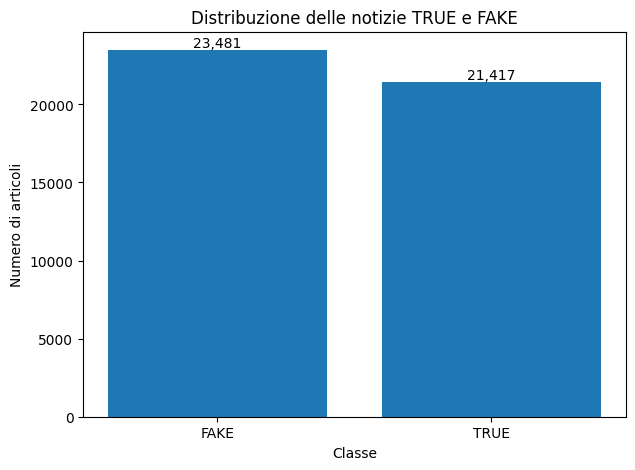

Percentuale delle classi:
label
FAKE    52.3
TRUE    47.7
Name: proportion, dtype: float64


In [ ]:
# CELLA 11

import matplotlib.pyplot as plt

class_counts = dataset["label"].value_counts()

plt.figure(figsize=(7, 5))

bars = plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title("Distribuzione delle notizie TRUE e FAKE")
plt.xlabel("Classe")
plt.ylabel("Numero di articoli")

# Mostriamo il valore sopra ogni barra
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.show()

print("Percentuale delle classi:")
print((dataset["label"].value_counts(normalize=True) * 100).round(2))

<!-- CELLA 12 -->

### Osservazione

Il corpus risulta complessivamente ben bilanciato: il **52,3%** degli articoli appartiene alla classe FAKE e il **47,7%** alla classe TRUE.

La lieve prevalenza delle notizie false non è sufficientemente marcata da rendere necessarie tecniche specifiche di riequilibrio delle classi. In fase di valutazione, tuttavia, l'accuracy verrà affiancata da precision e recall per entrambe le classi, così da analizzare separatamente i diversi tipi di errore.

<!-- CELLA 13 -->

## 2.2 Distribuzione delle categorie tematiche

Analizziamo ora la variabile `subject`, che descrive la categoria associata a ciascun articolo.

Questa informazione è utile nell'analisi esplorativa, ma richiede particolare attenzione: se alcune categorie fossero associate esclusivamente a una delle due classi, il loro utilizzo come feature permetterebbe al classificatore di sfruttare una caratteristica della raccolta dei dati anziché il contenuto della notizia.

Per questo motivo osserviamo la distribuzione delle categorie separatamente per TRUE e FAKE.

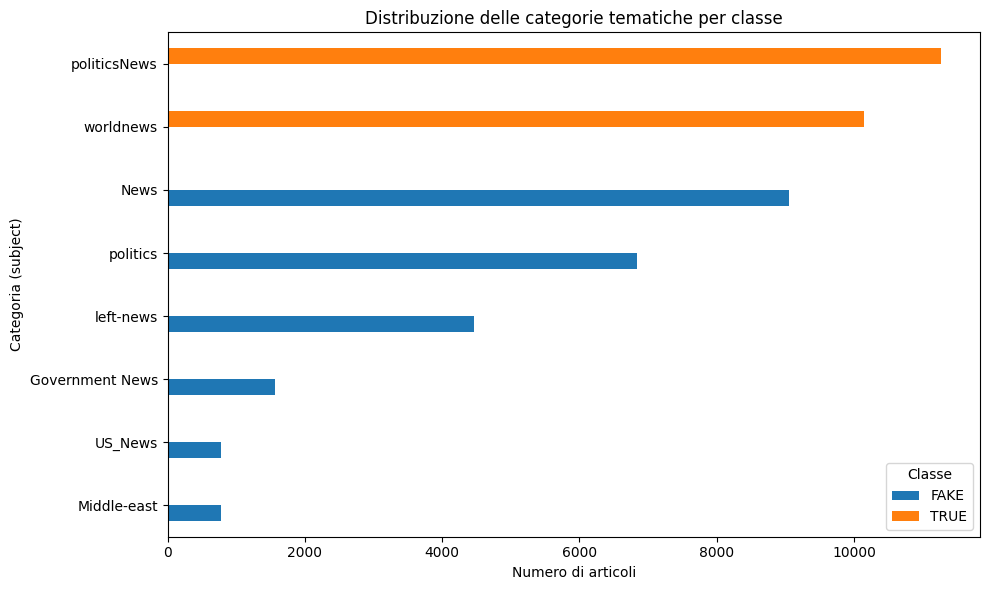

Percentuale TRUE/FAKE all'interno di ogni categoria:


label,FAKE,TRUE
subject,,
Government News,100.0,0.0
Middle-east,100.0,0.0
News,100.0,0.0
US_News,100.0,0.0
left-news,100.0,0.0
politics,100.0,0.0
politicsNews,0.0,100.0
worldnews,0.0,100.0


In [ ]:
# CELLA 14

# Conteggio degli articoli per subject e classe
subject_counts = (
    dataset.groupby(["subject", "label"])
    .size()
    .unstack(fill_value=0)
)

# Ordiniamo le categorie in base al numero totale di articoli
subject_counts["Totale"] = subject_counts.sum(axis=1)
subject_counts = subject_counts.sort_values("Totale", ascending=True)

# Il totale serve soltanto per ordinare e non viene mostrato nel grafico
plot_data = subject_counts.drop(columns="Totale")

# Grafico
ax = plot_data.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Distribuzione delle categorie tematiche per classe")
plt.xlabel("Numero di articoli")
plt.ylabel("Categoria (subject)")
plt.legend(title="Classe")
plt.tight_layout()
plt.show()

# Tabella con la percentuale di ciascuna classe all'interno della categoria
subject_percentages = pd.crosstab(
    dataset["subject"],
    dataset["label"],
    normalize="index"
) * 100

print("Percentuale TRUE/FAKE all'interno di ogni categoria:")
display(subject_percentages.round(2))

<!-- CELLA 15 -->

### Osservazione

La distribuzione delle categorie evidenzia una separazione completa tra i due archivi.

Le categorie `Government News`, `Middle-east`, `News`, `US_News`, `left-news` e `politics` compaiono esclusivamente negli articoli FAKE, mentre `politicsNews` e `worldnews` compaiono esclusivamente negli articoli TRUE.

La variabile `subject` costituisce quindi un forte **indicatore della provenienza del dato** e non necessariamente dell'attendibilità del contenuto. Utilizzarla come feature del classificatore produrrebbe un evidente rischio di **data leakage**, permettendo al modello di distinguere le due fonti senza analizzare realmente il linguaggio degli articoli.

Per questo motivo `subject` verrà esclusa dalle variabili utilizzate per l'addestramento del classificatore, pur rimanendo utile per descrivere le caratteristiche del corpus.

<!-- CELLA 16 -->

## 2.3 Lunghezza dei titoli

Una delle caratteristiche richieste nell'analisi esplorativa riguarda la lunghezza dei titoli.

Poiché questa informazione potrebbe essere alterata dalle successive operazioni di preprocessing, viene calcolata direttamente sui titoli originali.

Consideriamo due misure:

- numero di caratteri del titolo;
- numero di parole del titolo.

Confrontiamo quindi TRUE e FAKE per verificare se una delle due classi presenta titoli sistematicamente più lunghi.

STATISTICHE SULLA LUNGHEZZA DEI TITOLI
---------------------------------------


title_char_length                        title_word_count               \
                   mean median    std min  max             mean median   std   
label                                                                          
FAKE              94.20   90.0  27.18   8  286            14.73   14.0  4.34   
TRUE              64.67   64.0   9.17  26  133             9.95   10.0  1.70   

               
      min max  
label          
FAKE    1  42  
TRUE    4  20

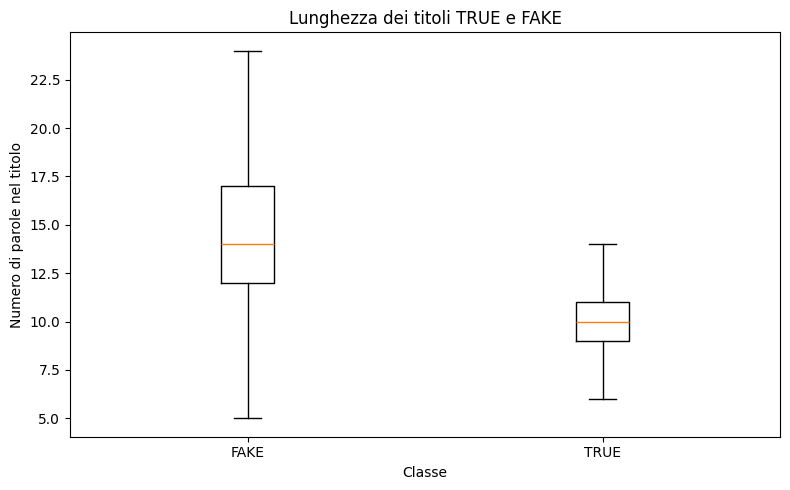

In [ ]:
# CELLA 17

# Calcoliamo la lunghezza dei titoli originali
dataset["title_char_length"] = dataset["title"].str.len()
dataset["title_word_count"] = dataset["title"].str.split().str.len()

# Statistiche descrittive per classe
title_stats = dataset.groupby("label")[
    ["title_char_length", "title_word_count"]
].agg(["mean", "median", "std", "min", "max"])

print("STATISTICHE SULLA LUNGHEZZA DEI TITOLI")
print("---------------------------------------")
display(title_stats.round(2))

# Boxplot del numero di parole nei titoli
fake_title_words = dataset.loc[
    dataset["label"] == "FAKE", "title_word_count"
]

true_title_words = dataset.loc[
    dataset["label"] == "TRUE", "title_word_count"
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [fake_title_words, true_title_words],
    tick_labels=["FAKE", "TRUE"],
    showfliers=False
)

plt.title("Lunghezza dei titoli TRUE e FAKE")
plt.xlabel("Classe")
plt.ylabel("Numero di parole nel titolo")
plt.tight_layout()
plt.show()

<!-- CELLA 18 -->

### Osservazione

I titoli delle notizie FAKE risultano sensibilmente più lunghi rispetto a quelli delle notizie TRUE.

In media, un titolo FAKE contiene circa **14,7 parole** contro le **10,0 parole** di un titolo TRUE. Anche considerando il numero di caratteri, la differenza rimane evidente: circa **94 caratteri** per le notizie FAKE contro **65** per quelle TRUE.

I titoli FAKE mostrano inoltre una maggiore variabilità nella lunghezza.

Questa differenza rappresenta una caratteristica stilistica rilevante del corpus, ma non deve essere interpretata automaticamente come una proprietà generale delle fake news: potrebbe dipendere anche dalle diverse fonti utilizzate per costruire i due archivi.

<!-- CELLA 19 -->

## 2.4 Uso delle maiuscole e della punteggiatura nei titoli

Titoli particolarmente enfatici possono fare maggiore uso di lettere maiuscole o punti esclamativi.

Poiché queste caratteristiche verrebbero eliminate durante il preprocessing, le analizziamo sul testo originale prima di procedere con la pulizia.

Per ogni titolo calcoliamo:

- la percentuale di lettere scritte in maiuscolo;
- il numero di parole completamente in maiuscolo;
- il numero di punti esclamativi;
- la percentuale di titoli contenenti almeno un punto esclamativo.

CARATTERISTICHE STILISTICHE DEI TITOLI
--------------------------------------


,uppercase_percentage,average_allcaps_words,average_exclamation_marks,titles_with_exclamation
label,,,,
FAKE,36.44,3.46,0.15,13.93
TRUE,6.71,0.62,0.00,0.08


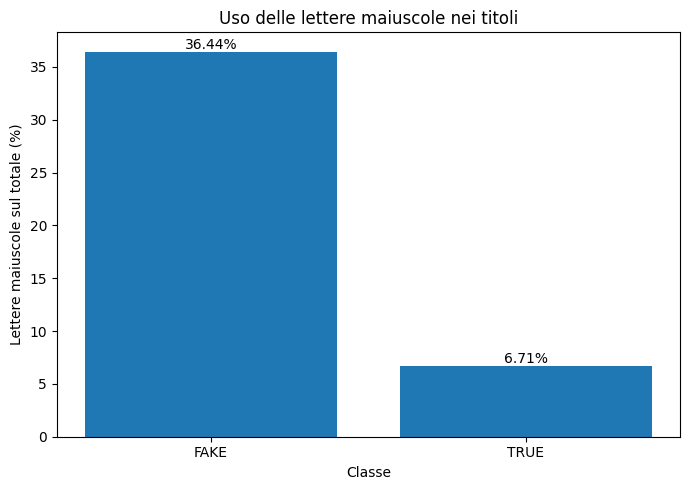

In [ ]:
# CELLA 20

import re

# Percentuale di lettere maiuscole sul totale delle lettere alfabetiche
def uppercase_ratio(text):
    letters = [char for char in text if char.isalpha()]

    if len(letters) == 0:
        return 0

    uppercase_letters = sum(char.isupper() for char in letters)

    return uppercase_letters / len(letters)


# Numero di parole completamente scritte in maiuscolo
def count_allcaps_words(text):
    words = re.findall(r"\b[\w'-]+\b", text)

    return sum(
        word.isupper() and any(char.isalpha() for char in word)
        for word in words
    )


dataset["title_uppercase_ratio"] = dataset["title"].apply(uppercase_ratio)

dataset["title_allcaps_words"] = dataset["title"].apply(
    count_allcaps_words
)

dataset["title_exclamation_count"] = dataset["title"].str.count("!")

dataset["title_has_exclamation"] = (
    dataset["title_exclamation_count"] > 0
)


# Statistiche per classe
style_stats = dataset.groupby("label").agg(
    uppercase_percentage=("title_uppercase_ratio", lambda x: x.mean() * 100),
    average_allcaps_words=("title_allcaps_words", "mean"),
    average_exclamation_marks=("title_exclamation_count", "mean"),
    titles_with_exclamation=("title_has_exclamation", lambda x: x.mean() * 100)
)

print("CARATTERISTICHE STILISTICHE DEI TITOLI")
print("--------------------------------------")
display(style_stats.round(2))


# Grafico: percentuale media di lettere maiuscole
uppercase_means = (
    dataset.groupby("label")["title_uppercase_ratio"]
    .mean() * 100
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    uppercase_means.index,
    uppercase_means.values
)

plt.title("Uso delle lettere maiuscole nei titoli")
plt.xlabel("Classe")
plt.ylabel("Lettere maiuscole sul totale (%)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

<!-- CELLA 21 -->

### Osservazione

Le differenze stilistiche tra i titoli TRUE e FAKE risultano molto marcate.

Nei titoli FAKE, in media, circa il **36,4% delle lettere alfabetiche è scritto in maiuscolo**, contro il **6,7%** dei titoli TRUE. Anche il numero medio di parole interamente in maiuscolo è superiore nelle notizie false (**3,46 contro 0,62**).

La differenza è particolarmente evidente anche nell'uso dei punti esclamativi: circa il **13,9%** dei titoli FAKE contiene almeno un punto esclamativo, mentre ciò avviene soltanto nello **0,08%** dei titoli TRUE.

Questi risultati indicano una forte differenza nello stile editoriale dei due archivi. Sebbene tali caratteristiche possano contribuire alla classificazione, non devono essere interpretate come indicatori universali di falsità: potrebbero riflettere le specifiche fonti da cui il corpus è stato raccolto.

<!-- CELLA 22 -->

## 2.5 Parole più frequenti nei titoli

Analizziamo ora il lessico utilizzato nei titoli delle due classi.

Per rendere il confronto più informativo:

- trasformiamo automaticamente il testo in minuscolo;
- ignoriamo le comuni stopwords inglesi;
- consideriamo soltanto singole parole;
- contiamo separatamente le occorrenze nei titoli TRUE e FAKE.

Questa analisi permette di individuare temi, personaggi o formule linguistiche particolarmente ricorrenti e può fornire ulteriori indizi su eventuali differenze tra le fonti del dataset.

15 PAROLE PIÙ FREQUENTI NEI TITOLI FAKE


,word,frequency
0,trump,9338
1,video,8477
2,obama,2582
3,hillary,2319
4,watch,1937
5,just,1409
6,president,1146
7,clinton,1138
8,new,905
9,breaking,896



15 PAROLE PIÙ FREQUENTI NEI TITOLI TRUE


,word,frequency
0,trump,5561
1,says,2981
2,house,1449
3,russia,977
4,north,926
5,korea,898
6,new,875
7,white,818
8,china,782
9,senate,759


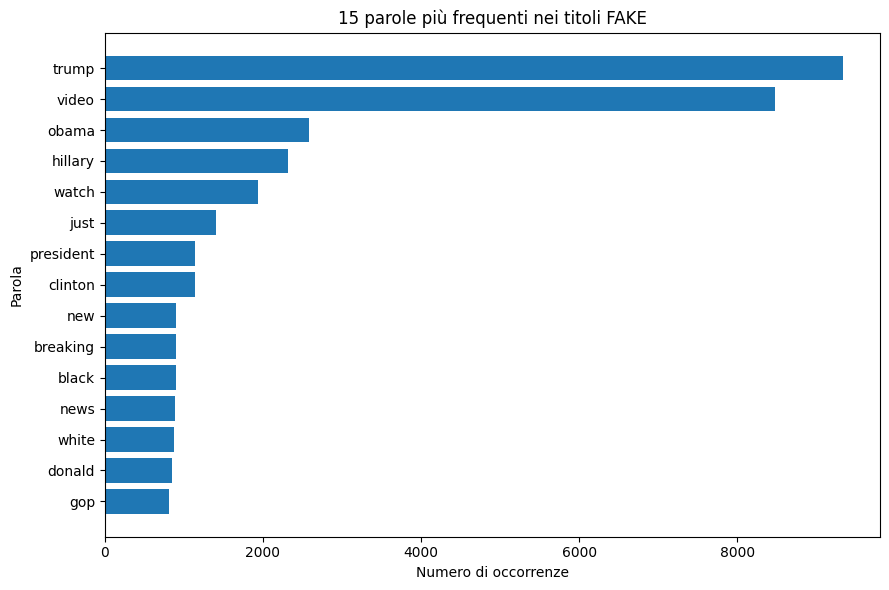

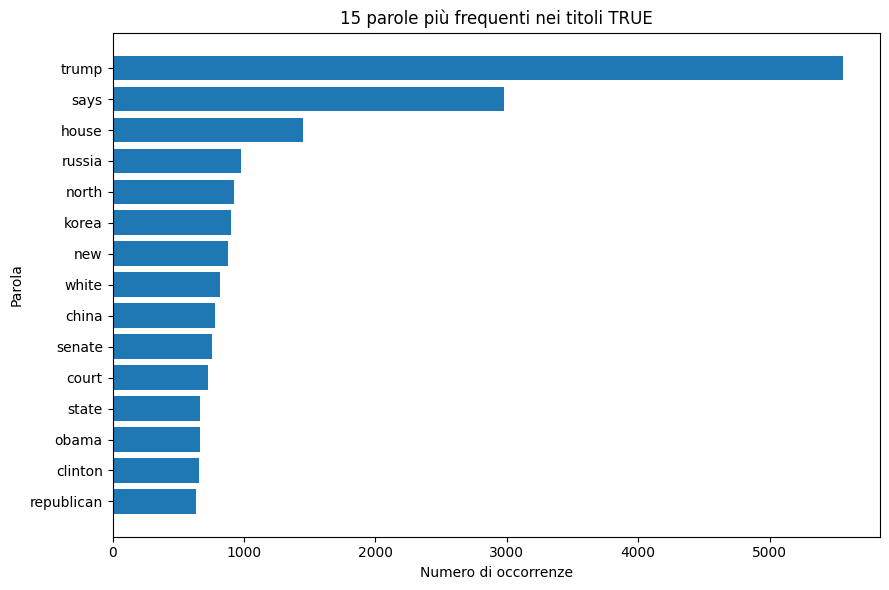

In [ ]:
# CELLA 23

from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import matplotlib.pyplot as plt


def most_frequent_words(titles, n_words=15):
    vectorizer = CountVectorizer(
        stop_words="english",
        lowercase=True
    )

    matrix = vectorizer.fit_transform(titles)

    word_counts = matrix.sum(axis=0).A1
    words = vectorizer.get_feature_names_out()

    frequency_df = pd.DataFrame({
        "word": words,
        "frequency": word_counts
    })

    return (
        frequency_df
        .sort_values("frequency", ascending=False)
        .head(n_words)
        .reset_index(drop=True)
    )


fake_top_words = most_frequent_words(
    dataset.loc[dataset["label"] == "FAKE", "title"]
)

true_top_words = most_frequent_words(
    dataset.loc[dataset["label"] == "TRUE", "title"]
)


print("15 PAROLE PIÙ FREQUENTI NEI TITOLI FAKE")
display(fake_top_words)

print("\n15 PAROLE PIÙ FREQUENTI NEI TITOLI TRUE")
display(true_top_words)


# Grafico FAKE
plt.figure(figsize=(9, 6))

plt.barh(
    fake_top_words["word"][::-1],
    fake_top_words["frequency"][::-1]
)

plt.title("15 parole più frequenti nei titoli FAKE")
plt.xlabel("Numero di occorrenze")
plt.ylabel("Parola")
plt.tight_layout()
plt.show()


# Grafico TRUE
plt.figure(figsize=(9, 6))

plt.barh(
    true_top_words["word"][::-1],
    true_top_words["frequency"][::-1]
)

plt.title("15 parole più frequenti nei titoli TRUE")
plt.xlabel("Numero di occorrenze")
plt.ylabel("Parola")
plt.tight_layout()
plt.show()

<!-- CELLA 24 -->

### Osservazione

L'analisi delle parole più frequenti nei titoli mostra differenze lessicali rilevanti tra le due classi.

Nei titoli FAKE sono particolarmente frequenti termini come `video`, `watch` e `breaking`, che possono riflettere uno stile editoriale più orientato a richiamare l'attenzione del lettore. Nei titoli TRUE compaiono invece con maggiore evidenza termini legati alla cronaca istituzionale e internazionale, come `says`, `house`, `russia`, `senate`, `court` e `china`.

Alcuni termini, come `trump`, `obama`, `clinton`, `white` e `new`, sono invece presenti tra le parole più frequenti di entrambe le classi e sembrano quindi descrivere soprattutto i temi del periodo considerato.

Anche queste differenze devono essere interpretate con cautela: possono derivare non soltanto dalla veridicità delle notizie, ma anche dalle diverse fonti editoriali che compongono i due archivi.

<!-- CELLA 25 -->

## 2.6 Verifica di un possibile source bias: Reuters

Durante la prima ispezione degli articoli TRUE è emersa frequentemente la formula `(Reuters) -` all'inizio del testo.

Questa caratteristica merita particolare attenzione: se il riferimento a Reuters fosse presente quasi esclusivamente nelle notizie TRUE, il classificatore potrebbe utilizzarlo come una scorciatoia per riconoscere la provenienza dell'articolo, anziché valutarne realmente il contenuto.

Misuriamo quindi quanto spesso il termine `Reuters` e la tipica formula editoriale `(Reuters) -` compaiono nelle due classi.

PRESENZA DI REUTERS NEL CORPUS
-----------------------------


,total_articles,articles_with_reuters,articles_with_reuters_signature,reuters_percentage,signature_percentage
label,,,,,
FAKE,23481,322,0,1.37,0.0
TRUE,21417,21378,21246,99.82,99.2


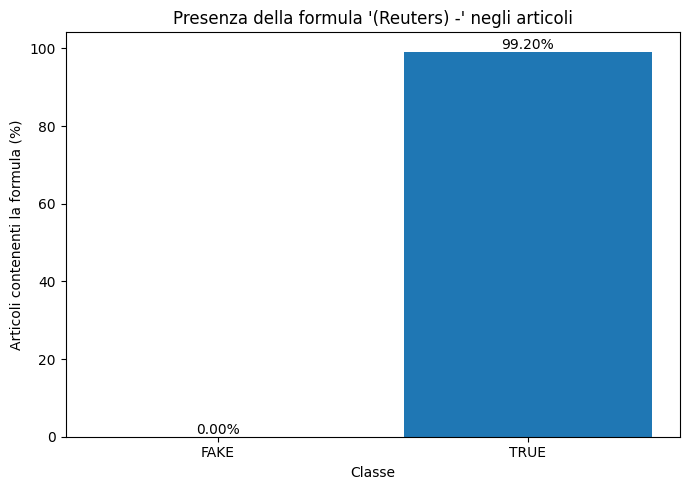

In [ ]:
# CELLA 26

# Presenza della parola Reuters nel testo
dataset["contains_reuters"] = (
    dataset["text"]
    .str.contains("Reuters", case=False, regex=False)
)

# Presenza della tipica formula editoriale "(Reuters) -"
dataset["contains_reuters_signature"] = (
    dataset["text"]
    .str.contains(r"\(Reuters\)\s*-", case=False, regex=True)
)

reuters_stats = dataset.groupby("label").agg(
    total_articles=("label", "size"),
    articles_with_reuters=("contains_reuters", "sum"),
    articles_with_reuters_signature=("contains_reuters_signature", "sum")
)

reuters_stats["reuters_percentage"] = (
    reuters_stats["articles_with_reuters"]
    / reuters_stats["total_articles"]
    * 100
)

reuters_stats["signature_percentage"] = (
    reuters_stats["articles_with_reuters_signature"]
    / reuters_stats["total_articles"]
    * 100
)

print("PRESENZA DI REUTERS NEL CORPUS")
print("-----------------------------")
display(reuters_stats.round(2))


# Grafico sulla formula editoriale "(Reuters) -"
signature_percentages = reuters_stats["signature_percentage"]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    signature_percentages.index,
    signature_percentages.values
)

plt.title("Presenza della formula '(Reuters) -' negli articoli")
plt.xlabel("Classe")
plt.ylabel("Articoli contenenti la formula (%)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

<!-- CELLA 27 -->

### Osservazione

L'analisi conferma la presenza di un fortissimo **source bias** nel corpus.

La parola `Reuters` compare nel **99,82%** degli articoli TRUE, mentre soltanto nell'**1,37%** degli articoli FAKE. Ancora più significativa è la tipica firma editoriale `(Reuters) -`, presente nel **99,20%** delle notizie TRUE e completamente assente dalle notizie FAKE.

Questa caratteristica potrebbe rendere la classificazione artificialmente semplice: un modello potrebbe imparare ad associare il riferimento a Reuters alla classe TRUE senza valutare realmente l'attendibilità del contenuto.

Per questo motivo, eventuali performance molto elevate dovranno essere interpretate con cautela. Nelle fasi successive verrà verificato quanto le caratteristiche legate alla fonte influenzino le decisioni del classificatore.

<!-- CELLA 28 -->

# 3. Preparazione del corpus

Prima di suddividere i dati in training e test è necessario controllare la presenza di articoli duplicati.

Se due copie dello stesso articolo venissero distribuite tra training e test, il modello potrebbe essere valutato su contenuti già incontrati durante l'addestramento, producendo una stima eccessivamente ottimistica delle performance.

Per il modello utilizzeremo come contenuto testuale la combinazione di **titolo e corpo dell'articolo**, mantenendo invece `subject` e `date` soltanto a fini esplorativi.

In [ ]:
# CELLA 29

# Creiamo il testo completo che verrà utilizzato successivamente dal modello
dataset["content"] = (
    dataset["title"].fillna("").str.strip()
    + " "
    + dataset["text"].fillna("").str.strip()
).str.strip()


# Duplicati esatti considerando titolo + testo
duplicate_content = dataset.duplicated(
    subset=["title", "text"],
    keep=False
)

print("CONTROLLO DEI DUPLICATI")
print("-----------------------")

print(
    "Articoli coinvolti in gruppi duplicati:",
    duplicate_content.sum()
)

print(
    "Copie eccedenti da rimuovere:",
    dataset.duplicated(
        subset=["title", "text"],
        keep="first"
    ).sum()
)


# Controlliamo anche se uno stesso contenuto compare con label diverse
label_per_content = (
    dataset.groupby(["title", "text"])["label"]
    .nunique()
)

cross_label_duplicates = (
    label_per_content > 1
).sum()

print(
    "\nContenuti identici presenti sia come TRUE sia come FAKE:",
    cross_label_duplicates
)


# Articoli con solo titolo e corpo del testo vuoto
empty_body = dataset["text"].str.strip().eq("")

print("\nARTICOLI CON TESTO VUOTO")
print("-----------------------")
print(dataset.loc[empty_body, "label"].value_counts())

print(
    "\nTutti gli articoli con testo vuoto hanno comunque un titolo:",
    dataset.loc[empty_body, "title"].str.strip().ne("").all()
)

CONTROLLO DEI DUPLICATI
-----------------------
Articoli coinvolti in gruppi duplicati: 11098
Copie eccedenti da rimuovere: 5793

Contenuti identici presenti sia come TRUE sia come FAKE: 0

ARTICOLI CON TESTO VUOTO
-----------------------
label
FAKE    630
TRUE      1
Name: count, dtype: int64

Tutti gli articoli con testo vuoto hanno comunque un titolo: True


<!-- CELLA 30 -->

#### Osservazione

Il controllo dei duplicati evidenzia una presenza consistente di articoli ripetuti: **5.793 righe rappresentano copie eccedenti di contenuti già presenti nel corpus**.

Mantenere questi duplicati potrebbe compromettere la valutazione del classificatore, perché copie dello stesso articolo potrebbero essere distribuite tra training e test, facendo apparire il modello più accurato di quanto sarebbe su contenuti realmente nuovi.

Non sono invece presenti articoli identici associati a classi differenti, quindi non emergono conflitti tra le etichette TRUE e FAKE.

Sono inoltre presenti alcuni articoli con corpo del testo vuoto, soprattutto nella classe FAKE. Poiché tutti dispongono comunque di un titolo e il modello utilizzerà la combinazione `title + text`, questi record vengono mantenuti.

<!-- CELLA 31 -->

## 3.1 Rimozione dei duplicati esatti

Per la fase di modellazione creiamo una copia del dataset priva degli articoli duplicati sulla combinazione di `title` e `text`.

Manteniamo separato il dataset originale utilizzato nell'analisi esplorativa, mentre `dataset_model` verrà utilizzato per le successive operazioni di preprocessing, suddivisione train/test e addestramento.

In [ ]:
# CELLA 32

# Creiamo il dataset destinato alla modellazione
dataset_model = (
    dataset
    .drop_duplicates(subset=["title", "text"], keep="first")
    .reset_index(drop=True)
    .copy()
)

rows_removed = len(dataset) - len(dataset_model)

print("RIMOZIONE DEI DUPLICATI")
print("-----------------------")
print("Articoli nel dataset originale:", len(dataset))
print("Duplicati rimossi:", rows_removed)
print("Articoli rimasti:", len(dataset_model))

print("\nDUPLICATI ESATTI ANCORA PRESENTI")
print("--------------------------------")
print(
    dataset_model.duplicated(
        subset=["title", "text"],
        keep=False
    ).sum()
)

print("\nDISTRIBUZIONE DELLE CLASSI DOPO LA RIMOZIONE")
print("--------------------------------------------")

class_distribution_clean = pd.DataFrame({
    "numero_articoli": dataset_model["label"].value_counts(),
    "percentuale": (
        dataset_model["label"].value_counts(normalize=True) * 100
    ).round(2)
})

display(class_distribution_clean)

print("\nARTICOLI CON TESTO VUOTO DOPO LA RIMOZIONE")
print("-------------------------------------------")
print(
    dataset_model.loc[
        dataset_model["text"].str.strip().eq(""),
        "label"
    ].value_counts()
)

RIMOZIONE DEI DUPLICATI
-----------------------
Articoli nel dataset originale: 44898
Duplicati rimossi: 5793
Articoli rimasti: 39105

DUPLICATI ESATTI ANCORA PRESENTI
--------------------------------
0

DISTRIBUZIONE DELLE CLASSI DOPO LA RIMOZIONE
--------------------------------------------


,numero_articoli,percentuale
label,,
TRUE,21197,54.21
FAKE,17908,45.79



ARTICOLI CON TESTO VUOTO DOPO LA RIMOZIONE
-------------------------------------------
label
FAKE    446
TRUE      1
Name: count, dtype: int64


<!-- CELLA 33 -->

#### Osservazione

Dopo la rimozione dei duplicati il corpus destinato alla modellazione contiene **39.105 articoli**.

La distribuzione delle classi rimane sufficientemente equilibrata:

- **54,21% TRUE**
- **45,79% FAKE**

Non vengono quindi applicate tecniche di riequilibrio delle classi.

Gli articoli con corpo del testo vuoto vengono mantenuti, poiché dispongono comunque di un titolo e l'input del classificatore sarà costituito dalla combinazione di titolo e testo.

<!-- CELLA 34 -->

## 3.2 Suddivisione in training e test set

Il dataset viene suddiviso in:

- **80% training set**, utilizzato per apprendere il modello;
- **20% test set**, utilizzato esclusivamente per valutarlo su articoli non impiegati durante l'addestramento.

La suddivisione viene effettuata utilizzando `stratify`, in modo da mantenere una proporzione simile di notizie TRUE e FAKE nei due insiemi.

Il test set viene mantenuto nel suo formato originale: le operazioni di pulizia verranno applicate successivamente senza modificare definitivamente i testi originali.

In [ ]:
# CELLA 35

from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    dataset_model,
    test_size=0.20,
    random_state=42,
    stratify=dataset_model["label"]
)

# Reset degli indici per lavorare più comodamente
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("SUDDIVISIONE TRAIN / TEST")
print("-------------------------")
print("Articoli totali:", len(dataset_model))
print("Training set:", len(train_df))
print("Test set:", len(test_df))

print("\nDISTRIBUZIONE DELLE CLASSI NEL TRAINING SET")
print("-------------------------------------------")
print(
    (train_df["label"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nDISTRIBUZIONE DELLE CLASSI NEL TEST SET")
print("---------------------------------------")
print(
    (test_df["label"].value_counts(normalize=True) * 100)
    .round(2)
)

SUDDIVISIONE TRAIN / TEST
-------------------------
Articoli totali: 39105
Training set: 31284
Test set: 7821

DISTRIBUZIONE DELLE CLASSI NEL TRAINING SET
-------------------------------------------
label
TRUE    54.21
FAKE    45.79
Name: proportion, dtype: float64

DISTRIBUZIONE DELLE CLASSI NEL TEST SET
---------------------------------------
label
TRUE    54.2
FAKE    45.8
Name: proportion, dtype: float64


<!-- CELLA 36 -->

# 4. Preprocessing e pulizia del testo

Prima di trasformare gli articoli in rappresentazioni numeriche, il testo viene normalizzato attraverso una funzione di pulizia unica e riutilizzabile.

La pipeline applica i principali passaggi affrontati nel corso:

- conversione del testo in minuscolo;
- rimozione della punteggiatura;
- lemmatizzazione;
- rimozione delle stopwords inglesi;
- rimozione dei numeri;
- eliminazione degli spazi superflui.

La lemmatizzazione viene preferita allo stemming perché consente di ricondurre le parole alla loro forma canonica mantenendo una maggiore coerenza linguistica.

La funzione viene progettata per poter essere richiamata sia sui dati di training e test sia, successivamente, su nuovi articoli da classificare.

In [ ]:
# CELLA 37

import spacy
import string
import re

# Modello linguistico inglese di spaCy
nlp = spacy.load(
    "en_core_web_sm",
    disable=["parser", "ner"]
)


def data_cleaner(dataset):
    dataset_to_return = []

    # Prima normalizziamo i testi
    texts = []

    for sentence in dataset:

        # Lowercase
        sentence = sentence.lower()

        # Rimozione della punteggiatura ASCII
        sentence = sentence.translate(
            str.maketrans(
                string.punctuation,
                " " * len(string.punctuation)
            )
        )

        # Rimozione dei numeri
        sentence = re.sub(r"\d+", " ", sentence)

        # Eliminazione degli spazi multipli
        sentence = re.sub(r"\s+", " ", sentence).strip()

        texts.append(sentence)

    # Lemmatizzazione e rimozione delle stopwords
    for document in nlp.pipe(
        texts,
        batch_size=100
    ):

        words = [
            token.lemma_.lower()
            for token in document
            if not token.is_stop
            and not token.is_punct
            and not token.is_space
        ]

        sentence_cleaned = " ".join(words)

        # Pulizia finale di eventuali simboli residui
        sentence_cleaned = re.sub(
            r"[^a-zA-Z\s]",
            " ",
            sentence_cleaned
        )

        sentence_cleaned = re.sub(
            r"\s+",
            " ",
            sentence_cleaned
        ).strip()

        dataset_to_return.append(sentence_cleaned)

    return dataset_to_return


# Verifica su tre articoli
sample_original = train_df["content"].head(3).tolist()
sample_cleaned = data_cleaner(sample_original)

for i, (original, cleaned) in enumerate(
    zip(sample_original, sample_cleaned),
    start=1
):
    print(f"\n--- ESEMPIO {i} ---")

    print("\nTESTO ORIGINALE:")
    print(original[:500])

    print("\nTESTO PULITO:")
    print(cleaned[:500])


--- ESEMPIO 1 ---

TESTO ORIGINALE:
ANOTHER CLINTON CASUALTY? Activist MURDERED After Openly Blaming HILLARY For Meddling Role In Honduran Coup [VIDEO] When far left publications like Democracy Now and Global Research start questioning Hillary s involvement in the murder of Honduran environmental activist, Berta C ceres, there is probably good reason to look a little deeper into the controversy. Former Secretary of State Hillary Clinton is facing a new round of questions about her handling of the 2009 coup in Honduras that ousted 

TESTO PULITO:
clinton casualty activist murder openly blame hillary meddle role honduran coup video far leave publication like democracy global research start question hillary s involvement murder honduran environmental activist berta c cere probably good reason look little deep controversy secretary state hillary clinton face new round question handling coup hondura oust democratically elect president manuel zelaya coup hondura violent place world week ind

<!-- CELLA 38 -->

## 4.1 Pulizia del training e del test set

La funzione di preprocessing viene ora applicata separatamente ai due insiemi.

I testi originali vengono mantenuti nel dataset, mentre il risultato della pulizia viene salvato in una nuova colonna denominata `content_clean`.

Questa separazione è utile perché consente di:

- conservare il contenuto originale per eventuali analisi successive;
- utilizzare esclusivamente la versione pulita nella codifica Bag of Words;
- applicare in futuro la stessa funzione a nuovi articoli da classificare.

La presenza di riferimenti editoriali come `Reuters` non viene modificata manualmente in questa prima versione della pipeline. Il loro eventuale effetto sul classificatore verrà analizzato successivamente.

In [ ]:
# CELLA 39

import time

start_time = time.time()

print("Pulizia del training set...")
train_df["content_clean"] = data_cleaner(
    train_df["content"].tolist()
)

print("Pulizia del test set...")
test_df["content_clean"] = data_cleaner(
    test_df["content"].tolist()
)

elapsed_time = time.time() - start_time

print("\nPREPROCESSING COMPLETATO")
print("-----------------------")
print("Training set pulito:", len(train_df["content_clean"]))
print("Test set pulito:", len(test_df["content_clean"]))
print(f"Tempo impiegato: {elapsed_time / 60:.2f} minuti")

print("\nTESTI VUOTI DOPO IL CLEANING")
print("---------------------------")
print(
    "Training:",
    train_df["content_clean"].str.strip().eq("").sum()
)
print(
    "Test:",
    test_df["content_clean"].str.strip().eq("").sum()
)

print("\nESEMPIO DI TESTO PULITO:")
print(train_df["content_clean"].iloc[0][:500])

Pulizia del training set...
Pulizia del test set...

PREPROCESSING COMPLETATO
-----------------------
Training set pulito: 31284
Test set pulito: 7821
Tempo impiegato: 14.40 minuti

TESTI VUOTI DOPO IL CLEANING
---------------------------
Training: 0
Test: 0

ESEMPIO DI TESTO PULITO:
clinton casualty activist murder openly blame hillary meddle role honduran coup video far leave publication like democracy global research start question hillary s involvement murder honduran environmental activist berta c cere probably good reason look little deep controversy secretary state hillary clinton face new round question handling coup hondura oust democratically elect president manuel zelaya coup hondura violent place world week indigenous environmental activist berta c ceres assassin


<!-- CELLA 40 -->

# 5. Codifica del testo tramite Bag of Words

I modelli di machine learning non possono lavorare direttamente sul testo, quindi gli articoli devono essere trasformati in una rappresentazione numerica.

Per questo progetto utilizziamo il **Bag of Words** tramite `CountVectorizer`, come visto durante il corso.

Il vocabolario viene limitato ai **10.000 termini più frequenti**. Questa scelta permette di:

- contenere la dimensionalità della matrice;
- ridurre il peso di termini estremamente rari;
- mantenere una rappresentazione sufficientemente ricca del corpus;
- rendere più gestibili tempi di addestramento e utilizzo della memoria.

Il vocabolario viene appreso **esclusivamente sul training set** tramite `fit_transform`. Il test set viene invece trasformato utilizzando lo stesso vocabolario tramite `transform`, evitando così che informazioni provenienti dai dati di test influenzino l'addestramento.

In [ ]:
# CELLA 41

from sklearn.feature_extraction.text import CountVectorizer

# Creazione del Bag of Words
vectorizer = CountVectorizer(
    max_features=10000
)

# Il vocabolario viene appreso soltanto sul training set
X_train = vectorizer.fit_transform(
    train_df["content_clean"]
)

# Il test set utilizza lo stesso vocabolario
X_test = vectorizer.transform(
    test_df["content_clean"]
)

y_train = train_df["label"]
y_test = test_df["label"]


print("BAG OF WORDS")
print("------------")

print("Dimensione training set:", X_train.shape)
print("Dimensione test set:", X_test.shape)

print(
    "\nNumero di termini nel vocabolario:",
    len(vectorizer.get_feature_names_out())
)

print(
    "\nTipo della matrice:",
    type(X_train)
)

print("\nPrimi 20 termini del vocabolario:")
print(vectorizer.get_feature_names_out()[:20])

BAG OF WORDS
------------
Dimensione training set: (31284, 10000)
Dimensione test set: (7821, 10000)

Numero di termini nel vocabolario: 10000

Tipo della matrice: <class 'scipy.sparse._csr.csr_matrix'>

Primi 20 termini del vocabolario:
['aapl' 'aaron' 'abadi' 'abandon' 'abbas' 'abbasi' 'abbott' 'abc'
 'abcpolitic' 'abd' 'abdel' 'abduct' 'abduction' 'abdul' 'abdullah' 'abe'
 'abedin' 'abhorrent' 'abid' 'abide']


<!-- CELLA 42 -->

# 6. Addestramento e valutazione dei classificatori

## 6.1 Multinomial Naive Bayes

Come primo modello utilizziamo **Multinomial Naive Bayes**, un classificatore particolarmente adatto a rappresentazioni testuali basate sul conteggio delle parole.

Il modello costituisce una baseline semplice e veloce da addestrare.

La valutazione viene effettuata esclusivamente sul test set, che non è stato utilizzato né per apprendere il vocabolario del Bag of Words né per addestrare il classificatore.

Oltre all'accuracy vengono considerate:

- **precision**, che indica quanto sono affidabili le predizioni assegnate a una classe;
- **recall**, che misura quanti esempi reali di una classe vengono riconosciuti correttamente;
- **F1-score**, che sintetizza precision e recall;
- **confusion matrix**, utile per distinguere i due diversi tipi di errore.

Questa distinzione è particolarmente importante nel contesto applicativo: classificare erroneamente una notizia vera come falsa può avere conseguenze diverse rispetto al mancato riconoscimento di una fake news.

MULTINOMIAL NAIVE BAYES
-----------------------
Accuracy: 0.9476
Tempo di addestramento: 0.06 secondi

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

        FAKE     0.9340    0.9528    0.9433      3582
        TRUE     0.9594    0.9431    0.9512      4239

    accuracy                         0.9476      7821
   macro avg     0.9467    0.9480    0.9473      7821
weighted avg     0.9478    0.9476    0.9476      7821



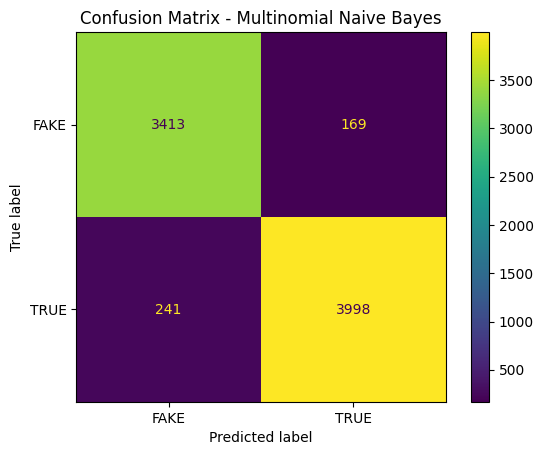

In [ ]:
# CELLA 43

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import time


# Creazione e addestramento del modello
model_nb = MultinomialNB()

start_time = time.time()

model_nb.fit(X_train, y_train)

training_time_nb = time.time() - start_time


# Predizioni sul test set
y_pred_nb = model_nb.predict(X_test)


# Accuracy
accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("MULTINOMIAL NAIVE BAYES")
print("-----------------------")
print(f"Accuracy: {accuracy_nb:.4f}")
print(f"Tempo di addestramento: {training_time_nb:.2f} secondi")

print("\nCLASSIFICATION REPORT")
print("---------------------")
print(
    classification_report(
        y_test,
        y_pred_nb,
        labels=["FAKE", "TRUE"],
        digits=4
    )
)


# Confusion Matrix
cm_nb = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=["FAKE", "TRUE"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=["FAKE", "TRUE"]
)

disp.plot()
plt.title("Confusion Matrix - Multinomial Naive Bayes")
plt.show()

<!-- CELLA 44 -->

### Risultati del Multinomial Naive Bayes

Il modello Multinomial Naive Bayes raggiunge un'**accuracy del 94,76%** sul test set.

Le performance risultano abbastanza equilibrate tra le due classi:

- la classe FAKE presenta un recall del **95,28%**;
- la classe TRUE presenta un recall del **94,31%**.

La confusion matrix mostra tuttavia due tipologie di errore:

- **169 notizie FAKE** vengono classificate come TRUE;
- **241 notizie TRUE** vengono classificate come FAKE.

Nel contesto applicativo, il secondo errore è particolarmente rilevante: segnalare come falsa una notizia attendibile può compromettere l'affidabilità percepita del sistema.

I risultati sono complessivamente elevati, ma devono essere interpretati tenendo conto dei forti indizi di source bias individuati durante l'analisi esplorativa, in particolare della presenza quasi sistematica del riferimento a Reuters negli articoli TRUE.

<!-- CELLA 45 -->

## 6.2 Rete neurale MLP

Come secondo approccio utilizziamo un **MLPClassifier (Multi-Layer Perceptron)** di scikit-learn, secondo la configurazione affrontata durante il corso.

Il modello riceve in input la stessa rappresentazione Bag of Words utilizzata dal Naive Bayes. In questo modo il confronto riguarda principalmente il classificatore e non una diversa rappresentazione dei dati.

La rete utilizza:

- un hidden layer di 100 neuroni;
- funzione di attivazione logistica;
- ottimizzatore Adam;
- massimo 100 iterazioni.

Anche questo modello viene valutato esclusivamente sul test set attraverso accuracy, precision, recall, F1-score e confusion matrix.

MLP CLASSIFIER
--------------
Accuracy: 0.9894
Tempo di addestramento: 91.69 secondi

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

        FAKE     0.9907    0.9860    0.9884      3582
        TRUE     0.9883    0.9922    0.9902      4239

    accuracy                         0.9894      7821
   macro avg     0.9895    0.9891    0.9893      7821
weighted avg     0.9894    0.9894    0.9894      7821



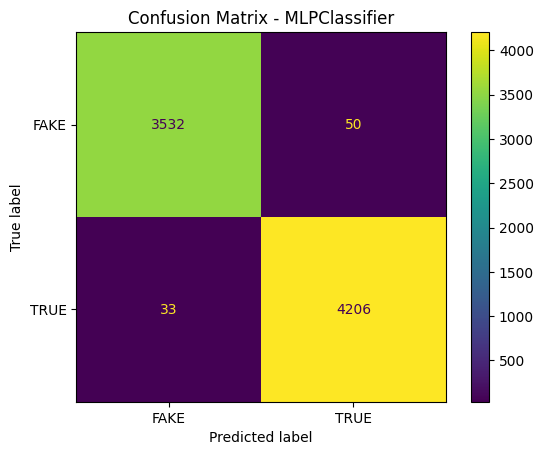

In [ ]:
# CELLA 46

from sklearn.neural_network import MLPClassifier

# Creazione del modello secondo la configurazione utilizzata nel corso
model_mlp = MLPClassifier(
    activation="logistic",
    solver="adam",
    max_iter=100,
    hidden_layer_sizes=(100,),
    tol=0.005,
    random_state=42,
    verbose=False
)

start_time = time.time()

# Addestramento
model_mlp.fit(X_train, y_train)

training_time_mlp = time.time() - start_time

# Predizioni sul test set
y_pred_mlp = model_mlp.predict(X_test)

# Accuracy
accuracy_mlp = accuracy_score(y_test, y_pred_mlp)

print("MLP CLASSIFIER")
print("--------------")
print(f"Accuracy: {accuracy_mlp:.4f}")
print(f"Tempo di addestramento: {training_time_mlp:.2f} secondi")

print("\nCLASSIFICATION REPORT")
print("---------------------")
print(
    classification_report(
        y_test,
        y_pred_mlp,
        labels=["FAKE", "TRUE"],
        digits=4
    )
)

# Confusion Matrix
cm_mlp = confusion_matrix(
    y_test,
    y_pred_mlp,
    labels=["FAKE", "TRUE"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=["FAKE", "TRUE"]
)

disp.plot()
plt.title("Confusion Matrix - MLPClassifier")
plt.show()

<!-- CELLA 47 -->

### Confronto tra i classificatori

I due modelli vengono ora confrontati utilizzando le stesse metriche e lo stesso test set.

Oltre all'accuracy, vengono riportati precision, recall e F1-score per entrambe le classi, insieme al tempo richiesto per l'addestramento.

Questo confronto consente di valutare non soltanto quale modello ottiene le prestazioni migliori, ma anche se l'aumento di complessità introdotto dalla rete neurale produce un beneficio sufficientemente rilevante rispetto al più semplice Naive Bayes.

In [ ]:
# CELLA 48

from sklearn.metrics import precision_recall_fscore_support

# Metriche Naive Bayes
precision_nb, recall_nb, f1_nb, _ = precision_recall_fscore_support(
    y_test,
    y_pred_nb,
    labels=["FAKE", "TRUE"]
)

# Metriche MLP
precision_mlp, recall_mlp, f1_mlp, _ = precision_recall_fscore_support(
    y_test,
    y_pred_mlp,
    labels=["FAKE", "TRUE"]
)

comparison = pd.DataFrame({
    "Modello": [
        "Multinomial Naive Bayes",
        "MLPClassifier"
    ],
    "Accuracy": [
        accuracy_nb,
        accuracy_mlp
    ],
    "Precision FAKE": [
        precision_nb[0],
        precision_mlp[0]
    ],
    "Recall FAKE": [
        recall_nb[0],
        recall_mlp[0]
    ],
    "F1 FAKE": [
        f1_nb[0],
        f1_mlp[0]
    ],
    "Precision TRUE": [
        precision_nb[1],
        precision_mlp[1]
    ],
    "Recall TRUE": [
        recall_nb[1],
        recall_mlp[1]
    ],
    "F1 TRUE": [
        f1_nb[1],
        f1_mlp[1]
    ],
    "Tempo addestramento (s)": [
        training_time_nb,
        training_time_mlp
    ]
})

comparison.iloc[:, 1:8] = comparison.iloc[:, 1:8].round(4)
comparison["Tempo addestramento (s)"] = (
    comparison["Tempo addestramento (s)"].round(2)
)

display(comparison)

,Modello,Accuracy,Precision FAKE,Recall FAKE,F1 FAKE,Precision TRUE,Recall TRUE,F1 TRUE,Tempo addestramento (s)
0,Multinomial Naive Bayes,0.9476,0.9340,0.9528,0.9433,0.9594,0.9431,0.9512,0.06
1,MLPClassifier,0.9894,0.9907,0.9860,0.9884,0.9883,0.9922,0.9902,91.69


<!-- CELLA 49 -->

### Osservazione sul confronto tra i modelli

La rete neurale MLP ottiene risultati sensibilmente migliori rispetto al Multinomial Naive Bayes.

L'accuracy passa dal **94,76%** del Naive Bayes al **98,94%** dell'MLPClassifier. Anche precision, recall e F1-score risultano superiori per entrambe le classi.

Particolarmente rilevante è la riduzione delle notizie TRUE erroneamente classificate come FAKE: il numero passa da **241** con Naive Bayes a **33** con l'MLP.

Il miglioramento ha però un costo computazionale evidente: come mostrano i tempi di addestramento, l'MLP richiede un tempo nettamente superiore rispetto al Naive Bayes. I valori assoluti possono variare in funzione dell'ambiente di esecuzione.

Le prestazioni quasi perfette della rete neurale richiedono inoltre una verifica più approfondita. L'analisi esplorativa ha già evidenziato forti differenze tra le fonti, quindi è necessario controllare se il modello stia realmente imparando caratteristiche associate all'attendibilità oppure sfruttando elementi editoriali specifici del corpus.

<!-- CELLA 50 -->

# 7. Interpretabilità e verifica del source bias

## 7.1 Termini maggiormente associati alle due classi

Il Multinomial Naive Bayes permette di osservare quali termini del vocabolario risultano maggiormente associati alle classi TRUE e FAKE.

Questa analisi è particolarmente utile per verificare se il modello utilizzi segnali linguisticamente plausibili oppure caratteristiche legate alla provenienza editoriale degli articoli.

Calcoliamo quindi, per ciascun termine, la differenza tra la probabilità appresa per la classe TRUE e quella appresa per la classe FAKE.

Un valore elevato in favore di una classe indica che quel termine è molto più caratteristico di quella classe all'interno del training set.

In [ ]:
# CELLA 51

import numpy as np
import pandas as pd

feature_names = vectorizer.get_feature_names_out()

# Individuiamo la posizione delle classi nel modello
fake_index = list(model_nb.classes_).index("FAKE")
true_index = list(model_nb.classes_).index("TRUE")

# Log-probabilità dei termini nelle due classi
fake_log_prob = model_nb.feature_log_prob_[fake_index]
true_log_prob = model_nb.feature_log_prob_[true_index]

# Differenza tra le log-probabilità
# valori positivi -> più associati a TRUE
# valori negativi -> più associati a FAKE
difference = true_log_prob - fake_log_prob

term_importance = pd.DataFrame({
    "term": feature_names,
    "score_TRUE_vs_FAKE": difference
})

top_true_terms = (
    term_importance
    .sort_values("score_TRUE_vs_FAKE", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

top_fake_terms = (
    term_importance
    .sort_values("score_TRUE_vs_FAKE", ascending=True)
    .head(20)
    .copy()
)

# Rendiamo positivo lo score nella tabella FAKE per una lettura più intuitiva
top_fake_terms["score_FAKE_vs_TRUE"] = (
    -top_fake_terms["score_TRUE_vs_FAKE"]
)

top_fake_terms = (
    top_fake_terms[
        ["term", "score_FAKE_vs_TRUE"]
    ]
    .reset_index(drop=True)
)


print("20 TERMINI MAGGIORMENTE ASSOCIATI ALLA CLASSE TRUE")
display(top_true_terms.round(3))

print("\n20 TERMINI MAGGIORMENTE ASSOCIATI ALLA CLASSE FAKE")
display(top_fake_terms.round(3))


# Analisi specifica del termine Reuters
if "reuters" in feature_names:

    reuters_position = np.where(
        feature_names == "reuters"
    )[0][0]

    reuters_score = difference[reuters_position]

    true_rank = (
        term_importance["score_TRUE_vs_FAKE"]
        .rank(method="min", ascending=False)
        .iloc[reuters_position]
    )

    print("\nANALISI DEL TERMINE 'reuters'")
    print("-----------------------------")
    print(f"Score TRUE vs FAKE: {reuters_score:.3f}")
    print(
        f"Posizione tra i termini più associati a TRUE: "
        f"{int(true_rank)} su {len(feature_names)}"
    )

else:
    print("\nIl termine 'reuters' non è presente nel vocabolario.")

20 TERMINI MAGGIORMENTE ASSOCIATI ALLA CLASSE TRUE


,term,score_TRUE_vs_FAKE
0,myanmar,7.631
1,rohingya,6.629
2,rakhine,6.411
3,zuma,6.181
4,puigdemont,6.067
5,hariri,5.994
6,suu,5.864
7,kyi,5.862
8,mnangagwa,5.745
9,rajoy,5.655



20 TERMINI MAGGIORMENTE ASSOCIATI ALLA CLASSE FAKE


,term,score_FAKE_vs_TRUE
0,https,8.129
1,getty,7.579
2,pic,7.106
3,quot,6.542
4,flickr,6.307
5,somodevilla,6.093
6,antifa,6.060
7,js,6.058
8,fjs,6.046
9,bundy,5.856



ANALISI DEL TERMINE 'reuters'
-----------------------------
Score TRUE vs FAKE: 5.371
Posizione tra i termini più associati a TRUE: 16 su 10000


<!-- CELLA 52 -->

### Interpretazione dei termini più discriminanti

L'analisi delle probabilità apprese dal Naive Bayes conferma i sospetti emersi durante l'EDA.

Il termine `reuters` occupa la **16ª posizione su 10.000 termini** tra quelli maggiormente associati alla classe TRUE. Questo risultato è coerente con la presenza quasi sistematica della firma Reuters negli articoli veri e costituisce un chiaro indizio di source bias.

Anche tra i termini associati alla classe FAKE emergono elementi come `https`, `getty`, `flickr`, `youtu`, `js`, `cdata` e `filessupport`. Molti di questi sembrano rappresentare URL, crediti multimediali o residui tecnici della raccolta dei contenuti piuttosto che caratteristiche linguistiche legate alla veridicità della notizia.

Sono inoltre presenti termini fortemente legati a specifici argomenti geopolitici. Ciò suggerisce che il classificatore possa sfruttare non soltanto lo stile editoriale, ma anche differenze nella copertura tematica dei due archivi.

Le elevate performance ottenute devono quindi essere considerate con cautela.

<!-- CELLA 53 -->

## 7.2 Presenza dei principali marcatori di fonte e artefatti tecnici

Per approfondire l'analisi, misuriamo la percentuale di documenti del training set che contiene alcuni dei termini sospetti emersi tra le feature più discriminanti.

L'obiettivo non è ancora rimuoverli, ma verificare se la loro presenza sia fortemente associata a una sola classe.

Questa analisi aiuterà a decidere in modo documentato quali caratteristiche trattare in un successivo esperimento di controllo del source bias.

In [ ]:
# CELLA 54

import re
import pandas as pd

# Termini chiaramente riconducibili a fonte, URL o artefatti tecnici
suspicious_terms = [
    "reuters",
    "https",
    "getty",
    "flickr",
    "youtu",
    "tmsnrt",
    "quot",
    "cdata",
    "filessupport"
]

results = []

for term in suspicious_terms:

    pattern = rf"\b{re.escape(term)}\b"

    for label in ["FAKE", "TRUE"]:

        texts = train_df.loc[
            train_df["label"] == label,
            "content_clean"
        ]

        percentage = (
            texts.str.contains(pattern, regex=True).mean()
            * 100
        )

        results.append({
            "term": term,
            "label": label,
            "document_percentage": percentage
        })


source_markers = pd.DataFrame(results)

source_markers_table = (
    source_markers
    .pivot(
        index="term",
        columns="label",
        values="document_percentage"
    )
    .fillna(0)
)

source_markers_table["difference"] = (
    source_markers_table["TRUE"]
    - source_markers_table["FAKE"]
).abs()

source_markers_table = (
    source_markers_table
    .sort_values("difference", ascending=False)
)

print("PERCENTUALE DI DOCUMENTI CONTENENTI I TERMINI")
print("---------------------------------------------")

display(source_markers_table.round(2))

PERCENTUALE DI DOCUMENTI CONTENENTI I TERMINI
---------------------------------------------


label,FAKE,TRUE,difference
term,,,
reuters,0.34,79.26,78.92
getty,22.50,0.01,22.49
https,13.74,0.00,13.74
flickr,3.08,0.00,3.08
filessupport,1.68,0.00,1.68
youtu,1.32,0.00,1.32
tmsnrt,0.00,1.29,1.29
cdata,0.57,0.00,0.57
quot,0.01,0.00,0.01


<!-- CELLA 55 -->

### Approfondimento sul termine Reuters dopo il preprocessing

Nel corpus originale il riferimento a Reuters era presente nella quasi totalità degli articoli TRUE, mentre dopo il preprocessing il token `reuters` compare in una percentuale inferiore.

Una possibile spiegazione è legata alla lemmatizzazione: dopo la conversione in minuscolo, spaCy potrebbe interpretare in alcuni contesti `reuters` come una forma flessa e ricondurla al lemma `reuter`.

Prima di definire i termini da rimuovere nell'esperimento sul source bias, verifichiamo quindi come il riferimento a Reuters viene rappresentato dopo il preprocessing.

In [ ]:
# CELLA 56

def percentage_with_term(series, term):
    pattern = rf"\b{re.escape(term)}\b"
    return series.str.contains(pattern, regex=True).mean() * 100


results_reuters = []

for label in ["FAKE", "TRUE"]:

    raw_texts = train_df.loc[
        train_df["label"] == label,
        "content"
    ]

    cleaned_texts = train_df.loc[
        train_df["label"] == label,
        "content_clean"
    ]

    # Reuters nel testo originale
    raw_reuters = (
        raw_texts
        .str.contains("Reuters", case=False, regex=False)
        .mean()
        * 100
    )

    # Diverse forme nel testo pulito
    cleaned_reuters = percentage_with_term(
        cleaned_texts,
        "reuters"
    )

    cleaned_reuter = percentage_with_term(
        cleaned_texts,
        "reuter"
    )

    cleaned_union = (
        cleaned_texts
        .str.contains(r"\breuters?\b", regex=True)
        .mean()
        * 100
    )

    results_reuters.append({
        "label": label,
        "Reuters nel testo originale (%)": raw_reuters,
        "'reuters' dopo cleaning (%)": cleaned_reuters,
        "'reuter' dopo cleaning (%)": cleaned_reuter,
        "'reuter' oppure 'reuters' (%)": cleaned_union
    })


reuters_preprocessing_check = pd.DataFrame(
    results_reuters
).set_index("label")

print("EFFETTO DEL PREPROCESSING SUL TERMINE REUTERS")
print("--------------------------------------------")

display(reuters_preprocessing_check.round(2))

EFFETTO DEL PREPROCESSING SUL TERMINE REUTERS
--------------------------------------------


,Reuters nel testo originale (%),'reuters' dopo cleaning (%),'reuter' dopo cleaning (%),'reuter' oppure 'reuters' (%)
label,,,,
FAKE,1.26,0.34,0.96,1.19
TRUE,99.81,79.26,36.28,99.81


<!-- CELLA 57 -->

### Interpretazione

La differenza osservata dopo il preprocessing è dovuta alla lemmatizzazione.

Nel training set, `Reuters` compare nel **99,81%** degli articoli TRUE originali. Dopo il cleaning, spaCy rappresenta il termine in parte come `reuters` e in parte come `reuter`; considerando entrambe le forme, la percentuale rimane esattamente **99,81%**.

Questo conferma che il riferimento alla fonte è ancora quasi perfettamente disponibile al classificatore.

Per valutare quanto tali segnali influenzino le performance, viene quindi realizzato un secondo esperimento in cui vengono rimossi esclusivamente alcuni marcatori chiaramente collegati alla fonte o al processo di raccolta dei dati, mantenendo invariato il contenuto tematico degli articoli.

<!-- CELLA 58 -->

## 7.3 Esperimento di controllo del source bias

Creiamo una seconda versione del corpus rimuovendo alcuni token individuati nell'analisi precedente come probabili **marcatori editoriali o artefatti tecnici**:

- `reuters` e `reuter`;
- `getty`;
- `https`;
- `flickr`;
- `youtu`;
- `tmsnrt`;
- `cdata`;
- `filessupport`;
- `quot`.

Questa operazione non ha lo scopo di produrre un dataset completamente privo di bias, ma di verificare quanto le performance del classificatore dipendano da alcune delle scorciatoie più evidenti.

Il testo pulito originale viene conservato; il corpus modificato viene salvato separatamente.

In [ ]:
# CELLA 59

source_markers_to_remove = {
    "reuters",
    "reuter",
    "getty",
    "https",
    "flickr",
    "youtu",
    "tmsnrt",
    "cdata",
    "filessupport",
    "quot"
}


def remove_source_markers(text):
    words = text.split()

    words = [
        word
        for word in words
        if word not in source_markers_to_remove
    ]

    return " ".join(words)


# Creiamo una seconda versione dei testi
train_df["content_clean_debiased"] = (
    train_df["content_clean"]
    .apply(remove_source_markers)
)

test_df["content_clean_debiased"] = (
    test_df["content_clean"]
    .apply(remove_source_markers)
)


# Controllo: Reuters/Reuter dovrebbero essere scomparsi
for label in ["FAKE", "TRUE"]:

    texts = train_df.loc[
        train_df["label"] == label,
        "content_clean_debiased"
    ]

    remaining_reuters = (
        texts
        .str.contains(r"\breuters?\b", regex=True)
        .mean()
        * 100
    )

    print(
        f"{label} - documenti con 'reuter/reuters' "
        f"dopo la rimozione: {remaining_reuters:.2f}%"
    )


print("\nESEMPIO PRIMA DELLA RIMOZIONE:")
print(train_df["content_clean"].iloc[1][:500])

print("\nESEMPIO DOPO LA RIMOZIONE:")
print(train_df["content_clean_debiased"].iloc[1][:500])

FAKE - documenti con 'reuter/reuters' dopo la rimozione: 0.00%
TRUE - documenti con 'reuter/reuters' dopo la rimozione: 0.00%

ESEMPIO PRIMA DELLA RIMOZIONE:
mexico express ire u s migration policy vow dialogue mexico city reuters senior mexican official express worry irritation u s counterpart president donald trump policy thursday side pledge dialogue sensitive migration trade security issue face neighbor mexico foreign interior minister luis videgaray miguel angel osorio chong speak reporter u s secretary state rex tillerson homeland security chief john kelly follow closed door meeting mexican capital

ESEMPIO DOPO LA RIMOZIONE:
mexico express ire u s migration policy vow dialogue mexico city senior mexican official express worry irritation u s counterpart president donald trump policy thursday side pledge dialogue sensitive migration trade security issue face neighbor mexico foreign interior minister luis videgaray miguel angel osorio chong speak reporter u s secretary state rex ti

<!-- CELLA 60 -->

## 7.4 Naive Bayes dopo la rimozione dei principali source markers

Per valutare l'effetto delle caratteristiche legate alla provenienza degli articoli, costruiamo un nuovo Bag of Words utilizzando la versione del corpus da cui sono stati rimossi i principali marcatori editoriali e tecnici individuati.

Manteniamo invariati:

- lo stesso training set e test set;
- il limite di 10.000 termini nel vocabolario;
- lo stesso algoritmo Multinomial Naive Bayes.

In questo modo, eventuali variazioni nelle performance possono essere interpretate come un'indicazione dell'importanza dei marcatori rimossi.

Questo esperimento non elimina necessariamente tutte le differenze tra le fonti, ma permette di misurare l'effetto di alcune delle scorciatoie più evidenti.

NAIVE BAYES - SOURCE MARKERS RIMOSSI
------------------------------------
Accuracy: 0.9357
Accuracy modello originale: 0.9476
Differenza: -0.0119
Tempo di addestramento: 0.06 secondi

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

        FAKE     0.9142    0.9486    0.9311      3582
        TRUE     0.9552    0.9247    0.9397      4239

    accuracy                         0.9357      7821
   macro avg     0.9347    0.9367    0.9354      7821
weighted avg     0.9364    0.9357    0.9358      7821



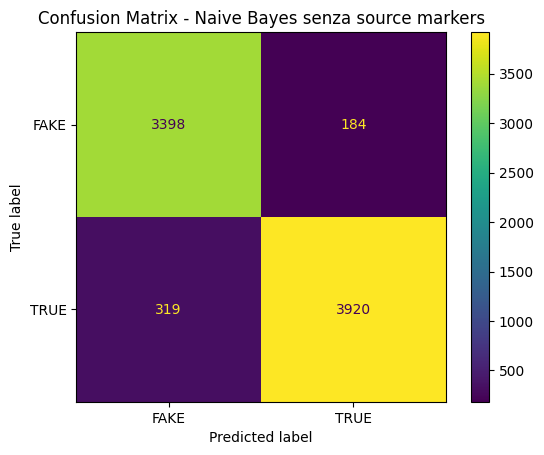

In [ ]:
# CELLA 61

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import time


# Nuovo Bag of Words sul corpus con i source markers rimossi
vectorizer_debiased = CountVectorizer(
    max_features=10000
)

X_train_debiased = vectorizer_debiased.fit_transform(
    train_df["content_clean_debiased"]
)

X_test_debiased = vectorizer_debiased.transform(
    test_df["content_clean_debiased"]
)


# Nuovo modello Naive Bayes
model_nb_debiased = MultinomialNB()

start_time = time.time()

model_nb_debiased.fit(
    X_train_debiased,
    y_train
)

training_time_nb_debiased = time.time() - start_time


# Predizioni
y_pred_nb_debiased = model_nb_debiased.predict(
    X_test_debiased
)


# Accuracy
accuracy_nb_debiased = accuracy_score(
    y_test,
    y_pred_nb_debiased
)


print("NAIVE BAYES - SOURCE MARKERS RIMOSSI")
print("------------------------------------")
print(f"Accuracy: {accuracy_nb_debiased:.4f}")
print(
    f"Accuracy modello originale: "
    f"{accuracy_nb:.4f}"
)

print(
    f"Differenza: "
    f"{accuracy_nb_debiased - accuracy_nb:+.4f}"
)

print(
    f"Tempo di addestramento: "
    f"{training_time_nb_debiased:.2f} secondi"
)


print("\nCLASSIFICATION REPORT")
print("---------------------")

print(
    classification_report(
        y_test,
        y_pred_nb_debiased,
        labels=["FAKE", "TRUE"],
        digits=4
    )
)


# Confusion Matrix
cm_nb_debiased = confusion_matrix(
    y_test,
    y_pred_nb_debiased,
    labels=["FAKE", "TRUE"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb_debiased,
    display_labels=["FAKE", "TRUE"]
)

disp.plot()

plt.title(
    "Confusion Matrix - Naive Bayes senza source markers"
)

plt.show()

<!-- CELLA 62 -->

### Effetto della rimozione dei source markers sul Naive Bayes

Dopo la rimozione dei principali marcatori editoriali e tecnici, l'accuracy del Multinomial Naive Bayes passa dal **94,76% al 93,57%**, con una riduzione di circa **1,19 punti percentuali**.

Il numero di notizie TRUE erroneamente classificate come FAKE aumenta da **241 a 319**, mentre le notizie FAKE classificate come TRUE passano da **169 a 184**.

Il calo delle prestazioni conferma che i marcatori individuati contribuivano alla classificazione. Tuttavia, l'accuracy rimane superiore al 93%, indicando che tali elementi non rappresentano l'unica fonte di separazione tra i due archivi.

È quindi probabile che il modello utilizzi anche altre differenze legate allo stile editoriale, agli argomenti trattati e alla composizione delle fonti. La rimozione effettuata deve essere interpretata come un esperimento di sensibilità al source bias, non come una completa eliminazione di tutti i possibili bias del corpus.

<!-- CELLA 63 -->

## 7.5 MLPClassifier dopo la rimozione dei source markers

Ripetiamo ora lo stesso esperimento utilizzando l'MLPClassifier, che nel corpus originale aveva raggiunto un'accuracy del **98,94%**.

Manteniamo invariata la configurazione della rete neurale e utilizziamo il nuovo Bag of Words costruito sul corpus con i principali source markers rimossi.

Il confronto permetterà di verificare quanto le performance particolarmente elevate dell'MLP dipendano dalle scorciatoie editoriali individuate.

MLP CLASSIFIER - SOURCE MARKERS RIMOSSI
---------------------------------------
Accuracy: 0.9841
Accuracy modello originale: 0.9894
Differenza: -0.0052
Tempo di addestramento: 85.03 secondi

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

        FAKE     0.9859    0.9793    0.9826      3582
        TRUE     0.9826    0.9882    0.9854      4239

    accuracy                         0.9841      7821
   macro avg     0.9843    0.9838    0.9840      7821
weighted avg     0.9842    0.9841    0.9841      7821



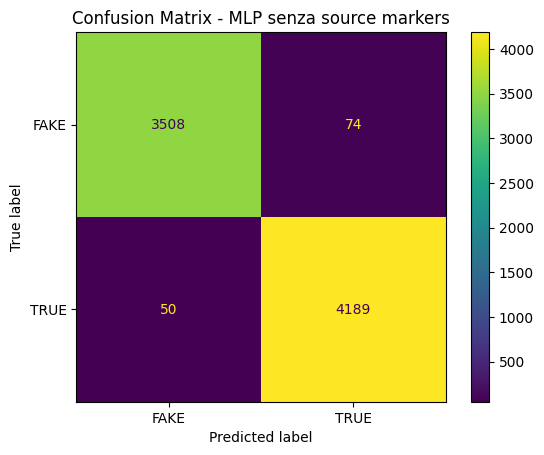

In [ ]:
# CELLA 64

from sklearn.neural_network import MLPClassifier

model_mlp_debiased = MLPClassifier(
    activation="logistic",
    solver="adam",
    max_iter=100,
    hidden_layer_sizes=(100,),
    tol=0.005,
    random_state=42,
    verbose=False
)

start_time = time.time()

# Addestramento sul corpus senza i source markers individuati
model_mlp_debiased.fit(
    X_train_debiased,
    y_train
)

training_time_mlp_debiased = time.time() - start_time


# Predizioni
y_pred_mlp_debiased = model_mlp_debiased.predict(
    X_test_debiased
)


# Accuracy
accuracy_mlp_debiased = accuracy_score(
    y_test,
    y_pred_mlp_debiased
)


print("MLP CLASSIFIER - SOURCE MARKERS RIMOSSI")
print("---------------------------------------")

print(f"Accuracy: {accuracy_mlp_debiased:.4f}")

print(
    f"Accuracy modello originale: "
    f"{accuracy_mlp:.4f}"
)

print(
    f"Differenza: "
    f"{accuracy_mlp_debiased - accuracy_mlp:+.4f}"
)

print(
    f"Tempo di addestramento: "
    f"{training_time_mlp_debiased:.2f} secondi"
)


print("\nCLASSIFICATION REPORT")
print("---------------------")

print(
    classification_report(
        y_test,
        y_pred_mlp_debiased,
        labels=["FAKE", "TRUE"],
        digits=4
    )
)


# Confusion Matrix
cm_mlp_debiased = confusion_matrix(
    y_test,
    y_pred_mlp_debiased,
    labels=["FAKE", "TRUE"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp_debiased,
    display_labels=["FAKE", "TRUE"]
)

disp.plot()

plt.title(
    "Confusion Matrix - MLP senza source markers"
)

plt.show()

<!-- CELLA 65 -->

### Effetto della rimozione dei source markers sull'MLPClassifier

Dopo la rimozione dei principali marcatori editoriali e tecnici, l'accuracy dell'MLPClassifier passa dal **98,94% al 98,41%**, con una riduzione di circa **0,52 punti percentuali**.

Il modello continua quindi a ottenere prestazioni molto elevate anche senza alcune delle scorciatoie più evidenti individuate nel corpus.

Questo risultato suggerisce che la separazione tra TRUE e FAKE non dipende soltanto da termini come `Reuters`, `Getty` o dagli artefatti legati agli URL. È probabile che rimangano altre differenze sistematiche tra i due archivi, tra cui stile editoriale, argomenti trattati, struttura dei testi e caratteristiche delle fonti originarie.

Di conseguenza, le performance del modello non devono essere interpretate come una misura definitiva della capacità di riconoscere fake news in contesti esterni a questo dataset.

<!-- CELLA 66 -->

## 7.6 Confronto complessivo degli esperimenti

Raccogliamo ora in un'unica tabella i risultati dei quattro esperimenti:

1. Naive Bayes sul corpus originale;
2. MLPClassifier sul corpus originale;
3. Naive Bayes dopo la rimozione dei principali source markers;
4. MLPClassifier dopo la rimozione dei principali source markers.

Oltre all'accuracy riportiamo precision, recall e F1-score per entrambe le classi, così da confrontare non soltanto le prestazioni complessive ma anche i diversi tipi di errore.

In [ ]:
# CELLA 67

from sklearn.metrics import precision_recall_fscore_support
import pandas as pd


def get_model_metrics(
    model_name,
    dataset_version,
    y_true,
    y_pred,
    training_time
):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=["FAKE", "TRUE"]
    )

    return {
        "Modello": model_name,
        "Corpus": dataset_version,
        "Accuracy": accuracy_score(y_true, y_pred),

        "Precision FAKE": precision[0],
        "Recall FAKE": recall[0],
        "F1 FAKE": f1[0],

        "Precision TRUE": precision[1],
        "Recall TRUE": recall[1],
        "F1 TRUE": f1[1],

        "Tempo training (s)": training_time
    }


final_comparison = pd.DataFrame([

    get_model_metrics(
        "Naive Bayes",
        "Originale",
        y_test,
        y_pred_nb,
        training_time_nb
    ),

    get_model_metrics(
        "MLPClassifier",
        "Originale",
        y_test,
        y_pred_mlp,
        training_time_mlp
    ),

    get_model_metrics(
        "Naive Bayes",
        "Source markers rimossi",
        y_test,
        y_pred_nb_debiased,
        training_time_nb_debiased
    ),

    get_model_metrics(
        "MLPClassifier",
        "Source markers rimossi",
        y_test,
        y_pred_mlp_debiased,
        training_time_mlp_debiased
    )

])


# Arrotondamento per una lettura più semplice
metric_columns = [
    "Accuracy",
    "Precision FAKE",
    "Recall FAKE",
    "F1 FAKE",
    "Precision TRUE",
    "Recall TRUE",
    "F1 TRUE"
]

final_comparison[metric_columns] = (
    final_comparison[metric_columns].round(4)
)

final_comparison["Tempo training (s)"] = (
    final_comparison["Tempo training (s)"].round(2)
)


print("CONFRONTO COMPLESSIVO DEI MODELLI")
print("---------------------------------")

display(final_comparison)

CONFRONTO COMPLESSIVO DEI MODELLI
---------------------------------


,Modello,Corpus,Accuracy,Precision FAKE,Recall FAKE,F1 FAKE,Precision TRUE,Recall TRUE,F1 TRUE,Tempo training (s)
0,Naive Bayes,Originale,0.9476,0.9340,0.9528,0.9433,0.9594,0.9431,0.9512,0.06
1,MLPClassifier,Originale,0.9894,0.9907,0.9860,0.9884,0.9883,0.9922,0.9902,91.69
2,Naive Bayes,Source markers rimossi,0.9357,0.9142,0.9486,0.9311,0.9552,0.9247,0.9397,0.06
3,MLPClassifier,Source markers rimossi,0.9841,0.9859,0.9793,0.9826,0.9826,0.9882,0.9854,85.03


<!-- CELLA 68 -->

### Scelta del modello finale

Tra le configurazioni sperimentate, viene selezionato come modello finale l'**MLPClassifier addestrato sul corpus con i principali source markers rimossi**.

L'MLP originale raggiunge l'accuracy più elevata (**98,94%**), ma può sfruttare marcatori fortemente associati alla provenienza degli articoli, come `Reuters`, `Getty` e riferimenti tecnici agli URL.

Dopo la rimozione di questi elementi, l'MLP mantiene comunque un'accuracy del **98,41%**, con:

- precision FAKE: **98,59%**;
- recall FAKE: **97,93%**;
- precision TRUE: **98,26%**;
- recall TRUE: **98,82%**.

La riduzione delle performance è quindi limitata, mentre il modello risulta meno dipendente da alcune delle scorciatoie editoriali più evidenti.

Questa correzione non elimina necessariamente tutti i bias presenti nel corpus: le due raccolte possono differire ancora per argomenti, stile e fonti originarie. Le metriche ottenute devono pertanto essere interpretate come performance sul dataset disponibile e non come garanzia di generalizzazione a tutte le notizie online.

<!-- CELLA 69 -->

# 8. Analisi degli errori del modello finale

La sola accuracy non permette di comprendere in quali situazioni il classificatore sbaglia.

Sul test set, il modello finale commette:

- **74 errori** in cui una notizia FAKE viene classificata come TRUE;
- **50 errori** in cui una notizia TRUE viene classificata come FAKE.

L'errore più frequente consiste quindi nel **non riconoscere una fake news**, anche se entrambi i tipi di errore rimangono poco frequenti.

Per comprendere meglio il comportamento del classificatore, analizziamo alcuni degli errori commessi con il livello di confidenza più elevato.

In [ ]:
# CELLA 70

import numpy as np
import pandas as pd

# Probabilità assegnate dal modello alle due classi
probabilities_final = model_mlp_debiased.predict_proba(
    X_test_debiased
)

# Indice della classe predetta per ogni articolo
predicted_class_index = np.argmax(
    probabilities_final,
    axis=1
)

# Confidenza associata alla previsione effettuata
prediction_confidence = probabilities_final[
    np.arange(len(probabilities_final)),
    predicted_class_index
]


# Creiamo una tabella con i risultati del test set
error_analysis = pd.DataFrame({
    "title": test_df["title"].values,
    "real_label": y_test.values,
    "predicted_label": y_pred_mlp_debiased,
    "confidence": prediction_confidence
})


# Manteniamo soltanto gli articoli classificati erroneamente
errors = error_analysis[
    error_analysis["real_label"]
    != error_analysis["predicted_label"]
].copy()

errors = errors.sort_values(
    "confidence",
    ascending=False
)


print("ANALISI DEGLI ERRORI DEL MODELLO FINALE")
print("---------------------------------------")
print("Numero totale di errori:", len(errors))

print("\nTipologia degli errori:")
print(
    errors.groupby(
        ["real_label", "predicted_label"]
    ).size()
)

print("\n5 ERRORI COMMESSI CON MAGGIORE CONFIDENZA")

display(
    errors[
        [
            "title",
            "real_label",
            "predicted_label",
            "confidence"
        ]
    ]
    .head(5)
    .round({"confidence": 4})
)

ANALISI DEGLI ERRORI DEL MODELLO FINALE
---------------------------------------
Numero totale di errori: 124

Tipologia degli errori:
real_label  predicted_label
FAKE        TRUE               74
TRUE        FAKE               50
dtype: int64

5 ERRORI COMMESSI CON MAGGIORE CONFIDENZA


,title,real_label,predicted_label,confidence
756,"Disillusionment, U.S.A. Where voters are just ...",TRUE,FAKE,1.0
5634,HOW DOES YOUR STATE’S ECONOMY RANK? Washington...,FAKE,TRUE,1.0
5471,N. KOREA’S LATEST MISSILE LAUNCH Aimed At Test...,FAKE,TRUE,1.0
1896,BREAKING: IRAN THROWS DOWN ULTIMATUM: …Your Mo...,FAKE,TRUE,1.0
6391,PRESIDENT TRUMP’S Illegal Immigrant Crackdown ...,FAKE,TRUE,1.0


<!-- CELLA 71 -->

### Osservazione sugli errori

Il modello finale commette **124 errori su 7.821 articoli di test**. Il tipo di errore più frequente consiste nel classificare come TRUE una notizia FAKE (**74 casi**), mentre **50 notizie TRUE** vengono erroneamente segnalate come FAKE.

L'analisi degli errori con maggiore confidenza mostra inoltre che il classificatore può essere molto sicuro anche quando sbaglia. Questo suggerisce di non interpretare direttamente le probabilità prodotte dall'MLP come una misura perfettamente calibrata dell'affidabilità della previsione.

Alcuni titoli erroneamente classificati presentano caratteristiche grafiche molto marcate, come l'uso delle maiuscole. Tuttavia, tali informazioni non vengono utilizzate direttamente dal modello principale, poiché il preprocessing converte il testo in minuscolo e rimuove la punteggiatura.

Il classificatore basa quindi la propria decisione principalmente sul contenuto lessicale degli articoli rappresentato tramite Bag of Words.

<!-- CELLA 72 -->

# 9. Classificazione di nuovi articoli

Prima di esportare il modello, definiamo una funzione riutilizzabile che riproduca l'intera pipeline necessaria per classificare un nuovo contenuto:

1. pulizia del testo tramite la funzione `data_cleaner`;
2. rimozione dei source markers individuati;
3. trasformazione tramite il Bag of Words già addestrato;
4. classificazione mediante l'MLPClassifier finale.

La funzione restituisce sia la classe prevista sia le probabilità associate alle due classi.

In [ ]:
# CELLA 73

def predict_news(text):
    # 1. Data cleaning
    cleaned_text = data_cleaner([text])[0]

    # 2. Rimozione dei source markers
    cleaned_text = remove_source_markers(cleaned_text)

    # 3. Bag of Words con il vocabolario già appreso
    vectorized_text = vectorizer_debiased.transform(
        [cleaned_text]
    )

    # 4. Predizione
    prediction = model_mlp_debiased.predict(
        vectorized_text
    )[0]

    probabilities = model_mlp_debiased.predict_proba(
        vectorized_text
    )[0]

    probability_dict = {
        label: probability
        for label, probability in zip(
            model_mlp_debiased.classes_,
            probabilities
        )
    }

    return prediction, probability_dict


# Due testi di prova scritti appositamente
example_1 = """
The United States Senate approved a new funding measure on Tuesday
after lawmakers reached an agreement following several days of negotiations.
Government officials said the measure will now move to the House for consideration.
"""

example_2 = """
BREAKING! Shocking secret plan exposed as government insiders reveal
the truth the mainstream media does not want Americans to know.
Millions of people are sharing the incredible story online.
"""


for i, example in enumerate(
    [example_1, example_2],
    start=1
):
    prediction, probabilities = predict_news(example)

    print(f"\nESEMPIO {i}")
    print("-" * 20)
    print("Predizione:", prediction)

    print(
        "Probabilità FAKE:",
        f"{probabilities['FAKE']:.4f}"
    )

    print(
        "Probabilità TRUE:",
        f"{probabilities['TRUE']:.4f}"
    )


ESEMPIO 1
--------------------
Predizione: TRUE
Probabilità FAKE: 0.0049
Probabilità TRUE: 0.9951

ESEMPIO 2
--------------------
Predizione: FAKE
Probabilità FAKE: 0.9998
Probabilità TRUE: 0.0002


<!-- CELLA 74 -->

### Test su nuovi contenuti

La pipeline viene verificata su due brevi testi scritti appositamente e non appartenenti al dataset.

Il primo esempio viene classificato come **TRUE** con probabilità elevata, mentre il secondo viene classificato come **FAKE**.

Questo test non rappresenta una misura aggiuntiva delle performance del modello, poiché i testi sono esempi sintetici e non dispongono di una validazione indipendente. Serve invece a verificare che l'intera pipeline possa elaborare correttamente un nuovo testo grezzo e produrre una previsione.

<!-- CELLA 75 -->

# 10. Esportazione del classificatore

Il modello deve poter essere utilizzato dal team che svilupperà l'estensione senza dover rieseguire l'addestramento del notebook.

Vengono quindi esportati:

- il modello MLPClassifier finale;
- il `CountVectorizer` con il vocabolario appreso sul training set;
- l'elenco dei source markers da rimuovere;
- le informazioni necessarie a ricostruire il preprocessing.

Gli oggetti vengono raccolti nel file `fake_news_classifier.pkl`.

Viene inoltre creato il modulo `fake_news_predictor.py`, che contiene le funzioni per:

1. caricare il classificatore esportato;
2. applicare lo stesso preprocessing utilizzato durante l'addestramento;
3. trasformare il testo tramite il vocabolario salvato;
4. restituire classe prevista e probabilità.

Infine, i file esportati vengono ricaricati e testati su nuovi testi per verificare che il sistema funzioni senza utilizzare direttamente gli oggetti presenti nella memoria del notebook.

In [ ]:
# CELLA 76

import pickle
import os
import textwrap

# ---------------------------------------------------------
# 1. SALVATAGGIO DEL MODELLO E DEGLI OGGETTI NECESSARI
# ---------------------------------------------------------

export_bundle = {
    "model": model_mlp_debiased,
    "vectorizer": vectorizer_debiased,
    "source_markers": source_markers_to_remove,
    "spacy_model": "en_core_web_sm",
    "model_name": "MLPClassifier",
    "classes": list(model_mlp_debiased.classes_),
    "max_features": 10000
}

pickle_path = "/content/fake_news_classifier.pkl"

with open(pickle_path, "wb") as file:
    pickle.dump(export_bundle, file)


# ---------------------------------------------------------
# 2. CREAZIONE DEL MODULO PER L'UTILIZZO DEL CLASSIFICATORE
# ---------------------------------------------------------

predictor_code = r'''
import pickle
import spacy
import string
import re


def load_classifier(pickle_path):
    """
    Carica modello, vectorizer e configurazione dal file pickle.
    """

    with open(pickle_path, "rb") as file:
        bundle = pickle.load(file)

    nlp = spacy.load(
        bundle["spacy_model"],
        disable=["parser", "ner"]
    )

    return bundle, nlp


def data_cleaner(dataset, nlp):
    """
    Applica lo stesso preprocessing utilizzato
    durante l'addestramento del modello.
    """

    dataset_to_return = []
    texts = []

    for sentence in dataset:

        sentence = sentence.lower()

        sentence = sentence.translate(
            str.maketrans(
                string.punctuation,
                " " * len(string.punctuation)
            )
        )

        sentence = re.sub(r"\d+", " ", sentence)
        sentence = re.sub(r"\s+", " ", sentence).strip()

        texts.append(sentence)

    for document in nlp.pipe(
        texts,
        batch_size=100
    ):

        words = [
            token.lemma_.lower()
            for token in document
            if not token.is_stop
            and not token.is_punct
            and not token.is_space
        ]

        sentence_cleaned = " ".join(words)

        sentence_cleaned = re.sub(
            r"[^a-zA-Z\s]",
            " ",
            sentence_cleaned
        )

        sentence_cleaned = re.sub(
            r"\s+",
            " ",
            sentence_cleaned
        ).strip()

        dataset_to_return.append(sentence_cleaned)

    return dataset_to_return


def remove_source_markers(text, source_markers):
    """
    Rimuove i principali marcatori editoriali
    individuati durante l'analisi del corpus.
    """

    words = text.split()

    words = [
        word
        for word in words
        if word not in source_markers
    ]

    return " ".join(words)


def predict_news(text, bundle, nlp):
    """
    Classifica un nuovo articolo come TRUE o FAKE.
    """

    cleaned_text = data_cleaner(
        [text],
        nlp
    )[0]

    cleaned_text = remove_source_markers(
        cleaned_text,
        bundle["source_markers"]
    )

    vectorized_text = bundle["vectorizer"].transform(
        [cleaned_text]
    )

    prediction = bundle["model"].predict(
        vectorized_text
    )[0]

    probabilities = bundle["model"].predict_proba(
        vectorized_text
    )[0]

    probability_dict = {
        label: float(probability)
        for label, probability in zip(
            bundle["model"].classes_,
            probabilities
        )
    }

    return prediction, probability_dict
'''

predictor_path = "/content/fake_news_predictor.py"

with open(predictor_path, "w") as file:
    file.write(textwrap.dedent(predictor_code))


# ---------------------------------------------------------
# 3. VERIFICA DEL RICARICAMENTO
# ---------------------------------------------------------

from fake_news_predictor import (
    load_classifier,
    predict_news as predict_news_exported
)

loaded_bundle, loaded_nlp = load_classifier(
    pickle_path
)


print("FILE ESPORTATI")
print("--------------")
print(
    "fake_news_classifier.pkl:",
    f"{os.path.getsize(pickle_path) / (1024**2):.2f} MB"
)

print(
    "fake_news_predictor.py:",
    f"{os.path.getsize(predictor_path) / 1024:.2f} KB"
)


print("\nTEST DEL MODELLO RICARICATO")
print("---------------------------")

for i, example in enumerate(
    [example_1, example_2],
    start=1
):

    prediction, probabilities = predict_news_exported(
        example,
        loaded_bundle,
        loaded_nlp
    )

    print(f"\nESEMPIO {i}")
    print("Predizione:", prediction)

    print(
        "Probabilità FAKE:",
        f"{probabilities['FAKE']:.4f}"
    )

    print(
        "Probabilità TRUE:",
        f"{probabilities['TRUE']:.4f}"
    )

FILE ESPORTATI
--------------
fake_news_classifier.pkl: 30.84 MB
fake_news_predictor.py: 2.56 KB

TEST DEL MODELLO RICARICATO
---------------------------

ESEMPIO 1
Predizione: TRUE
Probabilità FAKE: 0.0049
Probabilità TRUE: 0.9951

ESEMPIO 2
Predizione: FAKE
Probabilità FAKE: 0.9998
Probabilità TRUE: 0.0002


<!-- CELLA 77 -->

### Verifica dell'esportazione

L'esportazione del classificatore è stata completata correttamente.

Sono stati generati:

- `fake_news_classifier.pkl`, contenente il modello MLPClassifier, il `CountVectorizer`, il vocabolario appreso e la configurazione necessaria alla classificazione;
- `fake_news_predictor.py`, contenente le funzioni necessarie per applicare il preprocessing e classificare nuovi testi.

Il file pickle ha una dimensione di circa **30,84 MB**.

Dopo l'esportazione, il modello è stato ricaricato dai file appena creati e testato nuovamente sui due esempi precedenti. Le predizioni e le probabilità ottenute sono risultate identiche a quelle generate prima del salvataggio.

Questo conferma che il classificatore può essere riutilizzato senza dover rieseguire l'addestramento del notebook.

<!-- CELLA 78 -->

# 11. Conclusioni

Il progetto ha portato alla realizzazione di una pipeline completa per la classificazione automatica di articoli in lingua inglese nelle classi **TRUE** e **FAKE**.

Il corpus iniziale conteneva 44.898 articoli. Dopo la rimozione dei duplicati esatti, utilizzata per evitare possibili contaminazioni tra training e test set, sono rimasti **39.105 articoli**.

L'analisi esplorativa ha evidenziato differenze molto marcate tra i due archivi:

- le categorie `subject` separano completamente le classi TRUE e FAKE;
- i titoli FAKE risultano mediamente più lunghi;
- i titoli FAKE presentano un uso molto più frequente di lettere maiuscole e punti esclamativi;
- alcuni termini mostrano frequenze molto differenti tra le due raccolte;
- la quasi totalità degli articoli TRUE contiene un riferimento a Reuters.

Per evitare un evidente caso di data leakage, la variabile `subject` non è stata utilizzata nell'addestramento.

Il testo è stato sottoposto a lowercase, rimozione della punteggiatura e dei numeri, lemmatizzazione e rimozione delle stopwords. La rappresentazione numerica è stata costruita tramite **Bag of Words con un vocabolario massimo di 10.000 termini**.

Sono stati confrontati due classificatori:

- **Multinomial Naive Bayes**, che sul corpus originale ha raggiunto un'accuracy del **94,76%**;
- **MLPClassifier**, che sullo stesso corpus ha raggiunto un'accuracy del **98,94%**.

L'analisi dei termini maggiormente discriminanti ha tuttavia mostrato che entrambi i corpus contengono marcatori legati alla provenienza degli articoli. `Reuters`, ad esempio, è risultato il 16° termine maggiormente associato alla classe TRUE, mentre elementi come `Getty`, `https`, `Flickr` e altri residui tecnici risultavano fortemente associati alla classe FAKE.

È stato quindi effettuato un secondo esperimento rimuovendo alcuni dei principali source markers.

In questa configurazione:

- Naive Bayes ha raggiunto un'accuracy del **93,57%**;
- MLPClassifier ha raggiunto un'accuracy del **98,41%**.

La riduzione relativamente limitata delle performance mostra che i marcatori espliciti della fonte contribuiscono alla classificazione, ma non spiegano da soli l'elevata separabilità dei due archivi.

Come modello finale è stato selezionato l'**MLPClassifier addestrato sul corpus con i principali source markers rimossi**, poiché mantiene performance molto elevate riducendo almeno alcune delle scorciatoie editoriali più evidenti.

<!-- CELLA 79 -->

## 11.1 Limiti del modello

Nonostante le elevate performance sul test set, il classificatore presenta alcuni limiti importanti.

### Source bias

I dataset TRUE e FAKE provengono da raccolte differenti e presentano caratteristiche editoriali molto diverse. La presenza quasi sistematica di Reuters negli articoli TRUE rappresenta l'esempio più evidente, ma l'analisi mostra che esistono anche altre differenze legate a fonti, struttura e modalità di raccolta.

La rimozione di alcuni marcatori riduce il problema ma non garantisce che il corpus sia completamente privo di source bias.

### Differenze tematiche

Anche gli argomenti trattati dalle due raccolte non sono distribuiti nello stesso modo. Alcune parole fortemente associate a TRUE o FAKE possono quindi rappresentare soprattutto differenze nella copertura delle notizie, anziché segnali generali di attendibilità.

### Generalizzazione

L'accuracy del **98,41%** descrive le prestazioni su un test set estratto dallo stesso corpus utilizzato per lo sviluppo del modello.

Non può essere interpretata come una garanzia di ottenere la stessa accuratezza su articoli provenienti da testate, periodi storici o domini differenti.

### Confidenza delle predizioni

L'analisi degli errori mostra che l'MLP può produrre probabilità molto elevate anche in corrispondenza di previsioni errate.

Le probabilità restituite dal classificatore non dovrebbero quindi essere interpretate direttamente come una misura assoluta dell'attendibilità di una notizia.

<!-- CELLA 80 -->

## 11.2 Raccomandazioni per l'integrazione nel plug-in

Per l'utilizzo del classificatore nell'estensione Chrome si raccomanda di considerare il risultato del modello come **un'indicazione probabilistica e non come una certificazione automatica della veridicità di una notizia**.

In particolare:

- il plug-in dovrebbe evitare messaggi categorici come *"questa notizia è falsa"* e utilizzare formulazioni come *"contenuto classificato come probabilmente non attendibile"*;
- sarebbe opportuno definire una soglia di confidenza sotto la quale il sistema non produca una classificazione definitiva;
- il modello dovrebbe essere validato su fonti giornalistiche non presenti nel dataset di sviluppo;
- sarebbe utile costruire in futuro un test set proveniente da fonti e periodi temporali differenti, così da misurare meglio la capacità di generalizzazione;
- le performance dovrebbero essere monitorate nel tempo, poiché linguaggio, argomenti e modalità di diffusione della disinformazione possono cambiare;
- particolare attenzione dovrebbe essere dedicata ai **falsi positivi**, cioè alle notizie autentiche erroneamente segnalate come false.

Il modello sviluppato rappresenta quindi un prototipo con ottime performance sul corpus disponibile, ma una sua integrazione in un sistema destinato al pubblico richiede ulteriori verifiche su dati indipendenti.

In [ ]:
# CELLA 81

import zipfile
import os

export_zip_path = "/content/fake_news_model_export.zip"

with zipfile.ZipFile(
    export_zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    zip_file.write(
        "/content/fake_news_classifier.pkl",
        arcname="fake_news_classifier.pkl"
    )

    zip_file.write(
        "/content/fake_news_predictor.py",
        arcname="fake_news_predictor.py"
    )


print("PACCHETTO FINALE CREATO")
print("-----------------------")
print("File:", os.path.basename(export_zip_path))
print(
    "Dimensione:",
    f"{os.path.getsize(export_zip_path) / (1024**2):.2f} MB"
)

print("\nContenuto del pacchetto:")

with zipfile.ZipFile(export_zip_path, "r") as zip_file:
    for filename in zip_file.namelist():
        print("-", filename)

PACCHETTO FINALE CREATO
-----------------------
File: fake_news_model_export.zip
Dimensione: 29.26 MB

Contenuto del pacchetto:
- fake_news_classifier.pkl
- fake_news_predictor.py


<!-- CELLA 82 -->

## 11.3 Dipendenze per l'utilizzo esterno

Il classificatore esportato utilizza alcune librerie Python necessarie per caricare il modello e applicare lo stesso preprocessing utilizzato durante l'addestramento.

Per facilitare l'integrazione da parte del team di sviluppo, il pacchetto finale include:

- un file `requirements.txt` con le principali dipendenze;
- un breve `README.txt` con le istruzioni per il caricamento e l'utilizzo del classificatore.

Il modello linguistico spaCy `en_core_web_sm` deve essere disponibile nell'ambiente in cui viene eseguito il classificatore.

In [ ]:
# CELLA 83

import importlib.metadata
import zipfile
import os


# ---------------------------------------------------------
# 1. REQUIREMENTS.TXT
# ---------------------------------------------------------

packages = [
    "numpy",
    "scipy",
    "scikit-learn",
    "spacy"
]

requirements_lines = []

for package in packages:
    try:
        version = importlib.metadata.version(package)
        requirements_lines.append(
            f"{package}=={version}"
        )
    except importlib.metadata.PackageNotFoundError:
        requirements_lines.append(package)


requirements_path = "/content/requirements.txt"

with open(requirements_path, "w") as file:
    file.write("\n".join(requirements_lines))


# ---------------------------------------------------------
# 2. README.TXT
# ---------------------------------------------------------

readme_text = """
FAKE NEWS CLASSIFIER
====================

File inclusi
------------
- fake_news_classifier.pkl
  Contiene il modello MLPClassifier, il CountVectorizer
  e la configurazione necessaria alla classificazione.

- fake_news_predictor.py
  Contiene le funzioni per caricare il modello,
  preprocessare nuovi testi e produrre le predizioni.

- requirements.txt
  Contiene le principali dipendenze Python.


INSTALLAZIONE
-------------

1. Installare le dipendenze:

   pip install -r requirements.txt

2. Installare il modello linguistico spaCy:

   python -m spacy download en_core_web_sm


ESEMPIO DI UTILIZZO
-------------------

from fake_news_predictor import load_classifier, predict_news

bundle, nlp = load_classifier("fake_news_classifier.pkl")

text = "Insert the news article here."

prediction, probabilities = predict_news(
    text,
    bundle,
    nlp
)

print(prediction)
print(probabilities)


NOTA
----

Il classificatore restituisce una stima basata sul corpus
utilizzato durante lo sviluppo e non costituisce una
certificazione automatica della veridicità di una notizia.
"""

readme_path = "/content/README.txt"

with open(readme_path, "w") as file:
    file.write(readme_text.strip())


# ---------------------------------------------------------
# 3. RICREAZIONE DEL PACCHETTO FINALE
# ---------------------------------------------------------

export_zip_path = "/content/fake_news_model_export.zip"

with zipfile.ZipFile(
    export_zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    files_to_export = [
        "/content/fake_news_classifier.pkl",
        "/content/fake_news_predictor.py",
        "/content/requirements.txt",
        "/content/README.txt"
    ]

    for file_path in files_to_export:
        zip_file.write(
            file_path,
            arcname=os.path.basename(file_path)
        )


# ---------------------------------------------------------
# 4. VERIFICA
# ---------------------------------------------------------

print("PACCHETTO FINALE AGGIORNATO")
print("---------------------------")

print(
    "Dimensione:",
    f"{os.path.getsize(export_zip_path) / (1024**2):.2f} MB"
)

print("\nContenuto:")

with zipfile.ZipFile(export_zip_path, "r") as zip_file:
    for filename in zip_file.namelist():
        print("-", filename)

print("\nREQUIREMENTS")
print("------------")

with open(requirements_path, "r") as file:
    print(file.read())

PACCHETTO FINALE AGGIORNATO
---------------------------
Dimensione: 29.26 MB

Contenuto:
- fake_news_classifier.pkl
- fake_news_predictor.py
- requirements.txt
- README.txt

REQUIREMENTS
------------
numpy==2.1.3
scipy==1.16.3
scikit-learn==1.6.1
spacy==3.8.16


<!-- CELLA 84 -->

# 12. Pacchetto finale del modello

Il pacchetto `fake_news_model_export.zip` raccoglie tutti i file necessari per l'utilizzo del classificatore da parte del team di sviluppo:

- `fake_news_classifier.pkl`;
- `fake_news_predictor.py`;
- `requirements.txt`;
- `README.txt`.

Il file viene reso disponibile per il download al termine dell'esecuzione del notebook.

In [ ]:
# CELLA 85

from google.colab import files
import os

print("PACCHETTO PRONTO PER IL DOWNLOAD")
print("--------------------------------")
print("File:", os.path.basename(export_zip_path))
print(
    "Dimensione:",
    f"{os.path.getsize(export_zip_path) / (1024**2):.2f} MB"
)

files.download(export_zip_path)

PACCHETTO PRONTO PER IL DOWNLOAD
--------------------------------
File: fake_news_model_export.zip
Dimensione: 29.26 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>